In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import plotly.express as px
import seaborn as sns
members=pd.read_csv('members.csv')

In [2]:
members.shape

(13622, 21)

In [3]:
members.head()

,SiteID,HashID,JoinDate,Age,Gender,TitleID,PrimaryInd,LinkInd,PrimaryID,MemberType,...,HomePostCode,SubTypeID,SubDescription,PaymentMethodID,SubLevel1,SubLevel2,PaymentFreq,SubCategory,EnrolledInNextSteps,ContractType
0,CB,0xC2AC23BEF21E16A3968EFC3EC928436F2F1DFD00B20A...,2015-06-22,79,1,MRS,1,0,NaN,Primary,...,2602,CBSFF21,Sil Fit Fort Pre-Open,DDRBK,Silver/Fitness,F,F,21,Yes,On-going - 12 Month
1,CB,0xBC39C8DB3EE6066C2751987915D1403967DC149AC48F...,2022-09-29,72,1,MRS,1,0,NaN,Primary,...,2602,CBSFF03,Sil Fit Fort Classic,DDRBK,Silver/Fitness,F,F,3,Yes,On-going - 12 Month
2,CB,0x0AA92FCADB2F4DB2D33AAE81AB0BAF92A9F9EFD106AB...,2015-06-22,43,0,MR,1,0,NaN,Primary,...,2602,CBSFF21,Sil Fit Fort Pre-Open,DDRBK,Silver/Fitness,F,F,21,No,On-going - 12 Month
3,CB,0x0166B308374A9BFECBD065E1E14722BE67A37BDCC479...,2023-01-03,56,1,MRS,1,0,NaN,Primary,...,2602,CBGFF01,Gld Fit Fort Personal,DDRBK,Gold/Premium,F,F,1,Yes,On-going - 12 Month
4,CB,0xE58105310295CD5CF20471D510064481CAE698E05A89...,2015-06-22,82,0,DR,1,0,NaN,Primary,...,2602,CBSFF21,Sil Fit Fort Pre-Open,DDRBK,Silver/Fitness,F,F,21,No,On-going - 12 Month


In [4]:
members.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13622 entries, 0 to 13621
Data columns (total 21 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   SiteID               13622 non-null  object
 1   HashID               13622 non-null  object
 2   JoinDate             13622 non-null  object
 3   Age                  13622 non-null  int64 
 4   Gender               13622 non-null  int64 
 5   TitleID              13622 non-null  object
 6   PrimaryInd           13622 non-null  int64 
 7   LinkInd              13622 non-null  int64 
 8   PrimaryID            3870 non-null   object
 9   MemberType           13622 non-null  object
 10  FirstEnquiryDate     13615 non-null  object
 11  HomePostCode         12581 non-null  object
 12  SubTypeID            13622 non-null  object
 13  SubDescription       13622 non-null  object
 14  PaymentMethodID      13622 non-null  object
 15  SubLevel1            13622 non-null  object
 16  SubL

In [5]:
members.isnull().sum()

SiteID                    0
HashID                    0
JoinDate                  0
Age                       0
Gender                    0
TitleID                   0
PrimaryInd                0
LinkInd                   0
PrimaryID              9752
MemberType                0
FirstEnquiryDate          7
HomePostCode           1041
SubTypeID                 0
SubDescription            0
PaymentMethodID           0
SubLevel1                 0
SubLevel2                 0
PaymentFreq               0
SubCategory               0
EnrolledInNextSteps       0
ContractType           1002
dtype: int64

In [6]:
members.nunique()

SiteID                     5
HashID                 13622
JoinDate                3878
Age                       99
Gender                     3
TitleID                   13
PrimaryInd                 2
LinkInd                    2
PrimaryID               2382
MemberType                 2
FirstEnquiryDate        4096
HomePostCode             446
SubTypeID                406
SubDescription           245
PaymentMethodID            6
SubLevel1                  3
SubLevel2                  2
PaymentFreq                4
SubCategory               40
EnrolledInNextSteps        2
ContractType               4
dtype: int64

In [7]:
members['HashID'].duplicated().sum()

np.int64(0)

In [8]:
#check columns
categorical_columns= ['SiteID', 'Gender', 'TitleID', 'PrimaryInd', 'LinkInd',
                    'MemberType', 'PaymentMethodID', 'SubLevel1', 'SubLevel2',
                    'PaymentFreq', 'EnrolledInNextSteps', 'ContractType']

for column in categorical_columns:
    print('\n', column)
    print(members[column].value_counts(dropna=False))


 SiteID
SiteID
MD    3497
RY    3019
KP    2611
CB    2538
DC    1957
Name: count, dtype: int64

 Gender
Gender
1    6856
0    6717
2      49
Name: count, dtype: int64

 TitleID
TitleID
MR       5360
MRS      2616
MS       2429
MISS     1699
MAST     1024
DR        312
DRF       108
UNKNO      49
PROF        9
SIR         8
PROFF       4
HON         2
REV         2
Name: count, dtype: int64

 PrimaryInd
PrimaryInd
1    9752
0    3870
Name: count, dtype: int64

 LinkInd
LinkInd
0    9752
1    3870
Name: count, dtype: int64

 MemberType
MemberType
Primary    9752
Link       3870
Name: count, dtype: int64

 PaymentMethodID
PaymentMethodID
DDRBK    7917
DDRCC    3980
CASH     1683
CRD        34
DDEP        4
CHQ         4
Name: count, dtype: int64

 SubLevel1
SubLevel1
Silver/Fitness    9416
Gold/Premium      4183
Platinum            23
Name: count, dtype: int64

 SubLevel2
SubLevel2
A    7909
F    5713
Name: count, dtype: int64

 PaymentFreq
PaymentFreq
F    11064
A     1183
M     1035
C

In [9]:
#data dictionary
data_dictionary = pd.read_excel('Data_Dictionary1.xlsx')
data_dictionary.shape

(15, 4)

In [10]:
data_dictionary.head(30)

,NextGen <> USYD — data dictionary,Unnamed: 1,Unnamed: 2,Unnamed: 3
0,NaN,NaN,NaN,NaN
1,Cutoff date T0,midnight of 2024-07-19,NaN,NaN
2,Key for every table,HashID,NaN,NaN
3,NaN,NaN,NaN,NaN
4,File,Rows,Columns,One row per
5,members.csv,13622,21,One row per membe; merge everything else onto ...
6,attendance.csv,2692253,3,One row per club entry. Many rows per member; ...
7,sales.csv,883294,12,One row per sales line item.
8,bookings.csv,709049,10,"One row per booking (class, court, PT session)."
9,demographics.csv,12258,3,MOSAIC segment append. 0 or 1 rows per member.


In [11]:
pd.ExcelFile('Data_Dictionary1.xlsx').sheet_names

['Overview',
 'members',
 'attendance',
 'sales',
 'bookings',
 'demographics',
 'train_labels']

In [12]:
members_dictionary = pd.read_excel('Data_Dictionary1.xlsx', sheet_name='members')
members_dictionary

,members.csv — One row per member. Merge everything else onto this.,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5
0,"13,622 rows x 21 columns",NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN
2,Column,Type,Description,Values / notes,Distinct,Blank
3,SiteID,String,Club the member belongs to.,"CB, DC, KP, MD, RY",5,0
4,HashID,String,Unique member identifier. The key that joins e...,"66-char hex, unique per member","13,622",0
5,JoinDate,Date,The first day they joined NextGen.,1990-01-01 to 2023-07-21,"3,878",0
6,Age,Number,Age in years. NOTE: recorded as at the data ex...,3 to 126,99,0
7,Gender,Number,Gender code.,"0, 1, 2",3,0
8,TitleID,String,Title.,"MR, MRS, MS, MISS, DR, ...",13,0
9,PrimaryInd,Boolean,1 if they are the primary member — the person ...,"1, 0",2,0


In [13]:
#check age
members['Age'].describe()

count    13622.00000
mean        47.11408
std         22.55084
min          3.00000
25%         32.00000
50%         50.00000
75%         64.00000
max        126.00000
Name: Age, dtype: float64

In [14]:
members['Age'].sort_values().head(20)

10271    3
2393     3
13532    3
10442    3
13610    3
10441    3
6879     3
13608    3
7012     3
2407     3
2444     3
10324    3
2525     3
2523     3
2212     3
13402    3
2302     3
6924     3
6946     3
10366    3
Name: Age, dtype: int64

In [15]:
members['Age'].sort_values(ascending=False).head(20)

7385    126
4511    126
4897    126
4520    126
4242    126
4241    126
1086    126
9436    126
4976    126
9152    126
9128    126
4668    126
9043    126
8761    126
8739    126
8570    126
8315    126
4513    126
4509    126
8283    126
Name: Age, dtype: int64

In [16]:
print('Under 18:', (members['Age'] < 18).sum())
print('Over 100:', (members['Age'] > 100).sum())

Under 18: 2112
Over 100: 56


In [17]:
members.loc[members['Age'] > 100,
            ['HashID', 'Age', 'TitleID', 'MemberType', 'SubDescription']]

,HashID,Age,TitleID,MemberType,SubDescription
256,0x3ABA640C4F80757A3EA2AFCD03EE3356FCA48FFCFF6E...,126,MR,Primary,Gld Ace Complimentary Per
272,0x2BFC7A1A4D3B3938859E652F8D71FE348424D3595BA1...,126,MR,Primary,Sil Ace Comp Personal
670,0xC721391F8A9D1EABDBEFE9B2FF422DFFF5E17874018E...,126,MRS,Primary,Gld Fit Complimentary Per
1086,0xCB3A7378E12211A457C15831094D3DFC05D58BD756E9...,126,MR,Primary,Sil Ace Comp Personal
2423,0xCB49D67969A5D07C01055267EE84314FD2D3BA7A0F02...,126,MS,Link,Sil Ace Fort Linked Cub
2589,0x512488D91C5791689FB3A5199FAECC1596E34ED0C74D...,126,MR,Link,Fitness Fort Pers Preop20
4241,0x296DF1F45C9E96F881580DF0396F6DE8D4563A6D7B23...,126,MAST,Link,Fitness Complimentary Per
4242,0xFF0D0AD400802499B22C4DBBF303D495B5C90BF02884...,126,MISS,Link,Fitness Complimentary Per
4497,0x49DC2BD3D1F405267C6DE3CC58E7E4025B7C790CAD56...,126,MR,Primary,Gld Ace Comp K.P.F.M.
4501,0x7C1BA37001D833AD43305E2B9FB36CAB159917F28BB0...,126,MS,Primary,Gld Ace Comp K.P.F.M.


In [18]:
members.loc[members['Age'] < 18,
            ['Age', 'TitleID', 'MemberType', 'SubDescription']].head(30)

,Age,TitleID,MemberType,SubDescription
54,16,MAST,Link,Sil Ace Fort Linked Coll
55,15,MAST,Link,Sil Ace Fort Linked Coll
74,16,MISS,Link,Sil Ace Fort Linked Cub
75,14,MISS,Link,Sil Ace Fort Linked Cub
96,12,MAST,Link,Sil Ace Fort Linked Cub
100,16,MISS,Link,Sil Ace Fort Linked Cub
101,13,MAST,Link,Sil Ace Fort Linked Cub
103,12,MR,Link,Sil Ace Fort Linked Cub
124,13,MAST,Link,Sil Ace Fort Linked Cub
125,11,MAST,Link,Sil Ace Fort Linked Cub


In [19]:
members.loc[members['Age'] > 100, 'Age'].value_counts().sort_index()

Age
102     1
126    55
Name: count, dtype: int64

In [20]:
members.loc[members['Age'] == 126,
            ['Age', 'JoinDate', 'FirstEnquiryDate', 'TitleID',
             'MemberType', 'SubDescription']].head(60)

,Age,JoinDate,FirstEnquiryDate,TitleID,MemberType,SubDescription
256,126,2015-06-25,2015-06-25,MR,Primary,Gld Ace Complimentary Per
272,126,2015-06-29,2015-06-29,MR,Primary,Sil Ace Comp Personal
670,126,2016-09-05,2016-09-03,MRS,Primary,Gld Fit Complimentary Per
1086,126,2018-06-07,2018-06-07,MR,Primary,Sil Ace Comp Personal
2423,126,2023-05-31,2023-06-01,MS,Link,Sil Ace Fort Linked Cub
2589,126,2021-05-05,2019-11-11,MR,Link,Fitness Fort Pers Preop20
4241,126,2023-04-13,2023-04-13,MAST,Link,Fitness Complimentary Per
4242,126,2023-04-13,2023-04-13,MISS,Link,Fitness Complimentary Per
4497,126,2007-04-03,2007-04-03,MR,Primary,Gld Ace Comp K.P.F.M.
4501,126,2007-04-03,2007-04-03,MS,Primary,Gld Ace Comp K.P.F.M.


In [21]:
#check joindate and enquiry date
members['JoinDate'] = pd.to_datetime(members['JoinDate'])
members['FirstEnquiryDate'] = pd.to_datetime(members['FirstEnquiryDate'])

In [22]:
members[['JoinDate', 'FirstEnquiryDate']].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13622 entries, 0 to 13621
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   JoinDate          13622 non-null  datetime64[ns]
 1   FirstEnquiryDate  13615 non-null  datetime64[ns]
dtypes: datetime64[ns](2)
memory usage: 213.0 KB


In [23]:
members[['JoinDate', 'FirstEnquiryDate']].describe()

,JoinDate,FirstEnquiryDate
count,13622,13615
mean,2018-02-16 11:23:19.089707776,2017-02-15 16:39:22.805728768
min,1990-01-01 00:00:00,2006-11-14 00:00:00
25%,2015-09-27 06:00:00,2013-02-20 12:00:00
50%,2020-12-06 12:00:00,2018-09-17 00:00:00
75%,2022-08-22 00:00:00,2022-02-23 00:00:00
max,2023-07-21 00:00:00,2024-05-21 00:00:00


In [24]:
print('Earliest JoinDate:', members['JoinDate'].min())
print('Latest JoinDate:', members['JoinDate'].max())

print('Earliest FirstEnquiryDate:', members['FirstEnquiryDate'].min())
print('Latest FirstEnquiryDate:', members['FirstEnquiryDate'].max())

Earliest JoinDate: 1990-01-01 00:00:00
Latest JoinDate: 2023-07-21 00:00:00
Earliest FirstEnquiryDate: 2006-11-14 00:00:00
Latest FirstEnquiryDate: 2024-05-21 00:00:00


In [25]:
(members['FirstEnquiryDate'] > members['JoinDate']).sum()

np.int64(1082)

In [26]:
#check 1082(enquiry>join)
date_issue = members[members['FirstEnquiryDate'] > members['JoinDate']].copy()

date_issue['DifferenceDays'] = (date_issue['FirstEnquiryDate'] - date_issue['JoinDate']).dt.days

date_issue['DifferenceDays'].describe()

count     1082.000000
mean      1493.072089
std       1037.923599
min          1.000000
25%        711.250000
50%       1407.500000
75%       2388.000000
max      11275.000000
Name: DifferenceDays, dtype: float64

In [27]:
date_issue[['JoinDate', 'FirstEnquiryDate', 'DifferenceDays',
            'MemberType', 'SubDescription']].sort_values('DifferenceDays').head(20)

,JoinDate,FirstEnquiryDate,DifferenceDays,MemberType,SubDescription
248,2015-06-22,2015-06-23,1,Primary,Sil Fit Fort Personal
4088,2023-01-31,2023-02-01,1,Link,Premium Fort F Link
7022,2023-04-30,2023-05-01,1,Link,Sil Ace Fort Linked Cub
8482,2010-12-21,2010-12-22,1,Link,Gold Ace Fort F Link
3203,2021-11-27,2021-11-28,1,Link,Premium Fort Linked Cadet
8483,2010-12-21,2010-12-22,1,Link,Gold Ace Fort F Link
2423,2023-05-31,2023-06-01,1,Link,Sil Ace Fort Linked Cub
11134,2009-01-07,2009-01-08,1,Link,Sil Fit Mon Classic Cpl
5770,2016-09-20,2016-09-21,1,Link,Gold Ace Fort F Link
12360,2018-10-31,2018-11-01,1,Primary,Sil Ace Complimentary Per


In [28]:
date_issue[['JoinDate', 'FirstEnquiryDate', 'DifferenceDays','MemberType', 'SubDescription']].sort_values('DifferenceDays', ascending=False).head(20)

,JoinDate,FirstEnquiryDate,DifferenceDays,MemberType,SubDescription
6349,1990-01-01,2020-11-14,11275,Primary,Sil Fit Fort Personal
10599,1999-11-29,2023-10-19,8725,Link,Gld Ace Comp Platinum
10600,2000-07-17,2024-04-30,8688,Primary,Gld Ace Complimentary Per
2598,1999-04-04,2019-11-15,7530,Link,Premium Ann Linked Cub
2032,2002-07-12,2022-07-12,7305,Link,Sil Ace Fort Linked Cadet
9393,2000-01-14,2018-03-16,6636,Primary,Gld Ace Complimentary Per
9233,1999-11-29,2017-03-05,6306,Link,Gld Ace Comp Platinum
9234,1999-11-29,2017-03-05,6306,Link,Gld Ace Comp Platinum
13058,2010-09-30,2022-03-15,4184,Primary,Sil Ace Fort Classic
2536,2014-08-08,2024-05-21,3574,Primary,Sil Fit Fort Personal


In [29]:
(members['JoinDate'] == '1990-01-01').sum()

np.int64(2)

In [30]:
members.loc[members['JoinDate'] == '1990-01-01',
            ['JoinDate', 'FirstEnquiryDate', 'Age',
             'MemberType', 'SubDescription']]

,JoinDate,FirstEnquiryDate,Age,MemberType,SubDescription
6349,1990-01-01,2020-11-14,62,Primary,Sil Fit Fort Personal
10601,1990-01-01,NaT,126,Primary,Sil Ace Complimentary Per


In [31]:
#check homepostcode missing
members['HomePostCode'].isnull().mean()

np.float64(0.07642049625605637)

In [32]:
members.loc[members['HomePostCode'].isnull(), 'MemberType'].value_counts()

MemberType
Link       719
Primary    322
Name: count, dtype: int64

In [33]:
members.loc[members['HomePostCode'].isnull(), 'SiteID'].value_counts()

SiteID
DC    249
RY    222
KP    217
MD    189
CB    164
Name: count, dtype: int64

In [34]:
members.loc[members['HomePostCode'].isnull(), 'SubLevel1'].value_counts()

SubLevel1
Silver/Fitness    752
Gold/Premium      286
Platinum            3
Name: count, dtype: int64

In [35]:
members.groupby('MemberType')['HomePostCode'].apply(lambda x: x.isnull().mean())

MemberType
Link       0.185788
Primary    0.033019
Name: HomePostCode, dtype: float64

In [36]:
primary_postcode = members.loc[
    members['MemberType'] == 'Primary',
    ['HashID', 'HomePostCode']
].rename(columns={
    'HashID': 'PrimaryID',
    'HomePostCode': 'PrimaryPostCode'
})

In [37]:
#for linked
linked = members[members['MemberType'] == 'Link'].merge(
    primary_postcode,
    on='PrimaryID',
    how='left'
)

In [38]:
linked_missing = linked[linked['HomePostCode'].isnull()]

linked_missing['PrimaryPostCode'].notnull().value_counts()

PrimaryPostCode
True     529
False    190
Name: count, dtype: int64

In [39]:
linked_missing['PrimaryPostCode'].notnull().mean()

np.float64(0.7357440890125174)

In [40]:
linked_with_postcode = linked[
    linked['HomePostCode'].notnull() &
    linked['PrimaryPostCode'].notnull()
]

(linked_with_postcode['HomePostCode'] ==
 linked_with_postcode['PrimaryPostCode']).mean()

np.float64(0.9394572025052192)

In [41]:
print('Compared members:', len(linked_with_postcode))

print(
    (linked_with_postcode['HomePostCode'] ==
     linked_with_postcode['PrimaryPostCode']).value_counts()
)

Compared members: 2874
True     2700
False     174
Name: count, dtype: int64


In [42]:
members_clean = members.copy()

In [43]:
postcode_map = members_clean.loc[
    members_clean['MemberType'] == 'Primary'
].set_index('HashID')['HomePostCode']

In [44]:
mask = (
    (members_clean['MemberType'] == 'Link') &
    (members_clean['HomePostCode'].isnull())
)

members_clean.loc[mask, 'HomePostCode'] = (
    members_clean.loc[mask, 'PrimaryID'].map(postcode_map)
)

In [45]:
members_clean['HomePostCode'].isnull().sum()

np.int64(512)

In [46]:
members_clean.groupby('MemberType')['HomePostCode'].apply(
    lambda x: x.isnull().mean()
)

MemberType
Link       0.049096
Primary    0.033019
Name: HomePostCode, dtype: float64

In [47]:
#check contract type
members_clean.loc[members_clean['ContractType'].isnull(),'MemberType'].value_counts()

MemberType
Link       816
Primary    186
Name: count, dtype: int64

In [48]:
members_clean.groupby('MemberType')['ContractType'].apply(
    lambda x: x.isnull().mean()
)

MemberType
Link       0.210853
Primary    0.019073
Name: ContractType, dtype: float64

In [49]:
members_clean.groupby('SubLevel1')['ContractType'].apply(
    lambda x: x.isnull().mean()
)

SubLevel1
Gold/Premium      0.049964
Platinum          0.173913
Silver/Fitness    0.083794
Name: ContractType, dtype: float64

In [50]:
members_clean.groupby('PaymentFreq')['ContractType'].apply(
    lambda x: x.isnull().mean()
)

PaymentFreq
A    0.027895
C    0.291176
F    0.076555
M    0.022222
Name: ContractType, dtype: float64

In [51]:
#linked primary--contract type
primary_contract = members_clean.loc[
    members_clean['MemberType'] == 'Primary',
    ['HashID', 'ContractType']
].rename(columns={
    'HashID': 'PrimaryID',
    'ContractType': 'PrimaryContractType'
})

linked_contract = members_clean[
    members_clean['MemberType'] == 'Link'
].merge(
    primary_contract,
    on='PrimaryID',
    how='left'
)

In [52]:
linked_contract_missing = linked_contract[
    linked_contract['ContractType'].isnull()
]

linked_contract_missing['PrimaryContractType'].notnull().value_counts()

PrimaryContractType
True     697
False    119
Name: count, dtype: int64

In [53]:
linked_contract_known = linked_contract[
    linked_contract['ContractType'].notnull() &
    linked_contract['PrimaryContractType'].notnull()
]

print('Compared members:', len(linked_contract_known))

print(
    (linked_contract_known['ContractType'] ==
     linked_contract_known['PrimaryContractType']).value_counts()
)

print(
    'Agreement rate:',
    (linked_contract_known['ContractType'] ==
     linked_contract_known['PrimaryContractType']).mean()
)

Compared members: 2718
True     2415
False     303
Name: count, dtype: int64
Agreement rate: 0.8885209713024282


In [54]:
# ContractType missing values are retained
# Linked-primary agreement is 88.85%, so primary contract type is not considered reliable enough for imputation

In [55]:
# 55 records have Age = 126 and were flagged as potentially invalid.
# They will be treated when Age is used in subsequent analysis.

In [56]:
members_clean.loc[members_clean['Age'] == 126, 'Age'] = np.nan

members_clean['Age'].isnull().sum()

np.int64(55)

In [57]:
#check attendance

In [58]:
attendance = pd.read_csv('attendance.csv')

In [59]:
attendance.shape

(2692253, 3)

In [60]:
attendance.head()

,SiteID,HashID,ADateTime
0,DC,0x9C672C2164E01A90425F0682A77936E89B061E80F003...,2022-07-21 04:58:47.800
1,CB,0xCA7BFEE926232A0F0D5DCEBB27A4093CF8377B2F9F16...,2022-07-21 05:00:08.917
2,CB,0x452004B6505351439B5D66B72EAB53462ED76A91EAE0...,2022-07-21 05:00:09.860
3,CB,0x6E7745C2743ECACFC721B8440EEA259367E15FA4E4C8...,2022-07-21 05:00:13.677
4,CB,0xF81EBBDD4B001973A932E40842C72A9492EAF989B6DF...,2022-07-21 05:00:16.107


In [61]:
attendance.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2692253 entries, 0 to 2692252
Data columns (total 3 columns):
 #   Column     Dtype 
---  ------     ----- 
 0   SiteID     object
 1   HashID     object
 2   ADateTime  object
dtypes: object(3)
memory usage: 61.6+ MB


In [62]:
attendance.isnull().sum()

SiteID       0
HashID       0
ADateTime    0
dtype: int64

In [63]:
attendance.nunique()

SiteID             5
HashID         11945
ADateTime    2691821
dtype: int64

In [64]:
attendance['ADateTime'] = pd.to_datetime(attendance['ADateTime'])

attendance['ADateTime'].describe()

count                          2692253
mean     2023-07-28 14:21:56.035766528
min         2022-07-21 04:58:47.800000
25%         2023-02-07 10:26:21.820000
50%      2023-07-27 09:00:20.303000064
75%      2024-01-24 19:02:26.867000064
max         2024-07-19 21:54:24.493000
Name: ADateTime, dtype: object

In [65]:
print('Earliest:', attendance['ADateTime'].min())
print('Latest:', attendance['ADateTime'].max())

Earliest: 2022-07-21 04:58:47.800000
Latest: 2024-07-19 21:54:24.493000


In [66]:
T0 = pd.Timestamp('2024-07-19 23:59:59')

after_t0 = attendance[attendance['ADateTime'] > T0]

print('Records at/after T0:', len(after_t0))
print('Members affected:', after_t0['HashID'].nunique())

Records at/after T0: 0
Members affected: 0


In [67]:
after_t0['ADateTime'].describe()

count      0
mean     NaT
min      NaT
25%      NaT
50%      NaT
75%      NaT
max      NaT
Name: ADateTime, dtype: object

In [68]:
attendance_clean = attendance[
    attendance['ADateTime'] < T0
].copy()

In [69]:
print(attendance_clean.shape)
print(attendance_clean['ADateTime'].min())
print(attendance_clean['ADateTime'].max())

(2692253, 3)
2022-07-21 04:58:47.800000
2024-07-19 21:54:24.493000


In [70]:
attendance_clean.duplicated().sum()

np.int64(0)

In [71]:
#check memebrship cover
attendance_ids = set(attendance_clean['HashID'])
member_ids = set(members_clean['HashID'])

print('Attendance members:', len(attendance_ids))
print('Attendance IDs not in members:', len(attendance_ids - member_ids))
print('Members with no attendance:', len(member_ids - attendance_ids))

Attendance members: 11945
Attendance IDs not in members: 0
Members with no attendance: 1677


In [72]:
#connect to memeber level
attendance_features = (
    attendance_clean
    .groupby('HashID')
    .size()
    .reset_index(name='attendance_count')
)

attendance_features.head()

,HashID,attendance_count
0,0x0006E119B4404BD7E5195FFE981A420CDB7B3EC44395...,841
1,0x000B1B4D092FCEBF1A6CFBE93D78D1030CDE401F16BD...,116
2,0x000DB0844E141E35DA00166561851A3D00D0FF256F89...,4
3,0x000F2F278C0986A4F02057484F841AD1D33BD17C2ABF...,67
4,0x001024A62A9F1D7896BD2D0B65F2B5848C27D6753625...,25


In [73]:
attendance_features['attendance_count'].describe()

count    11945.000000
mean       225.387442
std        230.704514
min          1.000000
25%         61.000000
50%        157.000000
75%        311.000000
max       2553.000000
Name: attendance_count, dtype: float64

In [74]:
attendance_features.nlargest(10, 'attendance_count')

,HashID,attendance_count
1559,0x21BDA3218F56CBD8D73CAA660C317C37F9DF2ED299DF...,2553
693,0x0EF337E5B3F83B23180FA78C35FA76182B436B5C83A3...,1925
9825,0xD3E392113A0ABA59A0FCA54DF9D22E5E8EFE857DD513...,1814
5277,0x71300C6791E56CD28B677E7BA8E23FE92F6A85D7A519...,1802
4907,0x6A0EDD60AB5EB97A6E3A6356599D106D1D31DAC430BB...,1782
7699,0xA5F25532CE4C9C4BBB392A25EDAD51473AF74B720719...,1747
5378,0x733AEF73550A0D642E9607E05A75474B38F41990C5B3...,1746
6693,0x905224C536CCE6F63FC281251C2900BA3D652F60F8D9...,1741
1691,0x24983D9B28A97C67F74A81229C68BA4E04E6AE570BEF...,1609
943,0x14BF2709C107EC8851F8360D08F1B24D70B1B6D12614...,1594


In [75]:
#check active days
attendance_clean['AttendanceDate'] = attendance_clean['ADateTime'].dt.date

In [76]:
active_days = (
    attendance_clean
    .groupby('HashID')['AttendanceDate']
    .nunique()
    .reset_index(name='active_days')
)

active_days['active_days'].describe()

count    11945.000000
mean       142.849393
std        122.009752
min          1.000000
25%         46.000000
50%        113.000000
75%        208.000000
max        710.000000
Name: active_days, dtype: float64

In [77]:
attendance_features = attendance_features.merge(
    active_days,
    on='HashID',
    how='left'
)

attendance_features.nlargest(10, 'attendance_count')[
    ['HashID', 'attendance_count', 'active_days']
]

,HashID,attendance_count,active_days
1559,0x21BDA3218F56CBD8D73CAA660C317C37F9DF2ED299DF...,2553,653
693,0x0EF337E5B3F83B23180FA78C35FA76182B436B5C83A3...,1925,532
9825,0xD3E392113A0ABA59A0FCA54DF9D22E5E8EFE857DD513...,1814,637
5277,0x71300C6791E56CD28B677E7BA8E23FE92F6A85D7A519...,1802,691
4907,0x6A0EDD60AB5EB97A6E3A6356599D106D1D31DAC430BB...,1782,436
7699,0xA5F25532CE4C9C4BBB392A25EDAD51473AF74B720719...,1747,510
5378,0x733AEF73550A0D642E9607E05A75474B38F41990C5B3...,1746,596
6693,0x905224C536CCE6F63FC281251C2900BA3D652F60F8D9...,1741,608
1691,0x24983D9B28A97C67F74A81229C68BA4E04E6AE570BEF...,1609,469
943,0x14BF2709C107EC8851F8360D08F1B24D70B1B6D12614...,1594,538


In [78]:
#T0 to last attendance
last_attendance = (
    attendance_clean
    .groupby('HashID')['ADateTime']
    .max()
    .reset_index(name='last_attendance')
)

last_attendance['days_since_last_attendance'] = (
    T0 - last_attendance['last_attendance']
).dt.days

In [79]:
last_attendance['days_since_last_attendance'].describe()

count    11945.000000
mean        51.905735
std        111.374880
min          0.000000
25%          1.000000
50%          6.000000
75%         40.000000
max        728.000000
Name: days_since_last_attendance, dtype: float64

In [80]:
attendance_features = attendance_features.merge(
    last_attendance[['HashID', 'days_since_last_attendance']],
    on='HashID',
    how='left'
)

In [81]:
attendance_features.head()

,HashID,attendance_count,active_days,days_since_last_attendance
0,0x0006E119B4404BD7E5195FFE981A420CDB7B3EC44395...,841,448,0
1,0x000B1B4D092FCEBF1A6CFBE93D78D1030CDE401F16BD...,116,61,87
2,0x000DB0844E141E35DA00166561851A3D00D0FF256F89...,4,4,239
3,0x000F2F278C0986A4F02057484F841AD1D33BD17C2ABF...,67,51,15
4,0x001024A62A9F1D7896BD2D0B65F2B5848C27D6753625...,25,25,403


In [82]:
print(attendance_features.shape)
print('Duplicate HashID:', attendance_features['HashID'].duplicated().sum())
print(attendance_features.isna().sum())

(11945, 4)
Duplicate HashID: 0
HashID                        0
attendance_count              0
active_days                   0
days_since_last_attendance    0
dtype: int64


In [83]:
#sales dataset
sales = pd.read_csv('sales.csv')
print(sales.shape)
sales.head()

(883294, 12)


,SiteID,HashID,SaleID,RaisedDate,DueDate,ProductID,ProductName,ProductCounter,Amount,Quantity,DepartmentName,DepartmentCategory
0,RY,0xDFC44F301C93EB113D30B75E16472D92F18BA5F62BD2...,25063955,2022-11-18 11:44:34.000,2022-11-18 00:00:00.000,RY22501931,Vegan Flapjacks,6,3.60,1,Counter Food,F&B
1,MD,0xC162055C2591736E3C5C8D5444F5FF17EEDB2E7412FA...,16944072,2023-11-05 12:46:56.000,2023-11-05 00:00:00.000,MD29901634,Small Chips,3,7.00,1,Mains,F&B
2,MD,0x3F5710453194012F735E8356B0676BF95602544F065C...,16554005,2022-12-03 13:38:06.000,2022-12-03 00:00:00.000,MD3150011,Coke Zero 600ml,3,4.55,1,Soft Drinks,F&B
3,MD,0x163928B0689FAC3BEBA2B39A12BA4DC753C1B3BEEE48...,16991988,2023-12-20 12:45:55.000,2023-12-20 00:00:00.000,MD2300123,Quesadilla Foh,1,8.30,1,Counter Food,F&B
4,CB,0xBFCE547216FF66B1E99781421F9729AE24E6EF2A4FEC...,63002619,2024-01-04 18:09:55.000,2024-01-04 00:00:00.000,CB30000288,Capital Coast Ale,1,8.30,1,Beer,F&B


In [84]:
sales.info()
sales.isnull().sum()
sales.nunique()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 883294 entries, 0 to 883293
Data columns (total 12 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   SiteID              883294 non-null  object 
 1   HashID              883294 non-null  object 
 2   SaleID              883294 non-null  int64  
 3   RaisedDate          883294 non-null  object 
 4   DueDate             883294 non-null  object 
 5   ProductID           883294 non-null  object 
 6   ProductName         883294 non-null  object 
 7   ProductCounter      883294 non-null  int64  
 8   Amount              883294 non-null  float64
 9   Quantity            883294 non-null  int64  
 10  DepartmentName      883294 non-null  object 
 11  DepartmentCategory  883294 non-null  object 
dtypes: float64(1), int64(3), object(8)
memory usage: 80.9+ MB


SiteID                     5
HashID                 10695
SaleID                425921
RaisedDate            399398
DueDate                 3889
ProductID               3290
ProductName             2777
ProductCounter            50
Amount                  1421
Quantity                   9
DepartmentName            35
DepartmentCategory         5
dtype: int64

In [85]:
sales['RaisedDate'] = pd.to_datetime(sales['RaisedDate'])
sales['DueDate'] = pd.to_datetime(sales['DueDate'])

In [86]:
print('RaisedDate:')
print('Earliest:', sales['RaisedDate'].min())
print('Latest:', sales['RaisedDate'].max())

print('\nDueDate:')
print('Earliest:', sales['DueDate'].min())
print('Latest:', sales['DueDate'].max())

RaisedDate:
Earliest: 2022-07-21 05:37:43.643000
Latest: 2024-07-19 20:43:23

DueDate:
Earliest: 2022-02-06 00:00:00
Latest: 2024-08-20 00:00:00


In [87]:
sales_after_t0 = sales[sales['RaisedDate'] > T0]

print('Records at/after T0:', len(sales_after_t0))
print('Sales affected:', sales_after_t0['SaleID'].nunique())
print('Members affected:', sales_after_t0['HashID'].nunique())

Records at/after T0: 0
Sales affected: 0
Members affected: 0


In [88]:
sales_after_t0['RaisedDate'].describe()

count      0
mean     NaT
min      NaT
25%      NaT
50%      NaT
75%      NaT
max      NaT
Name: RaisedDate, dtype: object

In [89]:
sale_time_range = sales.groupby('SaleID')['RaisedDate'].agg(['min', 'max'])

cross_t0_sales = sale_time_range[
    (sale_time_range['min'] < T0) &
    (sale_time_range['max'] >= T0)
]

print('SaleIDs crossing T0:', len(cross_t0_sales))

SaleIDs crossing T0: 0


In [90]:
sales_clean = sales[sales['RaisedDate'] <= T0].copy()

In [91]:
#check amount and quantity
sales_clean[['Amount', 'Quantity']].describe()

,Amount,Quantity
count,883294.000000,883294.000000
mean,8.262374,1.003014
std,30.978157,0.114943
min,0.000100,1.000000
25%,2.700000,1.000000
50%,4.100000,1.000000
75%,7.200000,1.000000
max,1330.000000,15.000000


In [92]:
print('Negative Amount:', (sales_clean['Amount'] < 0).sum())
print('Zero Amount:', (sales_clean['Amount'] == 0).sum())

print('Negative Quantity:', (sales_clean['Quantity'] < 0).sum())
print('Zero Quantity:', (sales_clean['Quantity'] == 0).sum())

Negative Amount: 0
Zero Amount: 0
Negative Quantity: 0
Zero Quantity: 0


In [93]:
sales_clean['Quantity'].value_counts().sort_index()

Quantity
1     882125
2        749
3        143
4         53
5         18
6         20
7         13
8        172
15         1
Name: count, dtype: int64

In [94]:
sales_clean['Revenue'] = (
    sales_clean['Amount'] * sales_clean['Quantity']
)

In [95]:
sales_clean['Revenue'].describe()

count    883294.000000
mean          8.296856
std          31.036900
min           0.000100
25%           2.700000
50%           4.100000
75%           7.200000
max        1330.000000
Name: Revenue, dtype: float64

In [96]:
sales_clean.nlargest(10, 'Revenue')[
    ['SaleID', 'HashID', 'ProductName',
     'DepartmentCategory', 'Amount', 'Quantity', 'Revenue']
]

,SaleID,HashID,ProductName,DepartmentCategory,Amount,Quantity,Revenue
7709,16779581,0x53011079AC09B29B916519905F6B463D5E6C1D92D3C6...,P.T. 1hr X 20 Pack,Personal Training,1330.0,1,1330.0
10692,17220761,0x53011079AC09B29B916519905F6B463D5E6C1D92D3C6...,P.T. 1hr X 20 Pack,Personal Training,1330.0,1,1330.0
48799,16979087,0x53011079AC09B29B916519905F6B463D5E6C1D92D3C6...,P.T. 1hr X 20 Pack,Personal Training,1330.0,1,1330.0
183888,16704830,0x89E142BBF34D2A87762ABC26ADCF12251C16375A057E...,P.T. 1hr X 20 Pack,Personal Training,1330.0,1,1330.0
229517,16843412,0x89E142BBF34D2A87762ABC26ADCF12251C16375A057E...,P.T. 1hr X 20 Pack,Personal Training,1330.0,1,1330.0
243829,16938714,0x53011079AC09B29B916519905F6B463D5E6C1D92D3C6...,P.T. 1hr X 20 Pack,Personal Training,1330.0,1,1330.0
353463,16704834,0x53011079AC09B29B916519905F6B463D5E6C1D92D3C6...,P.T. 1hr X 20 Pack,Personal Training,1330.0,1,1330.0
452271,16804822,0x53011079AC09B29B916519905F6B463D5E6C1D92D3C6...,P.T. 1hr X 20 Pack,Personal Training,1330.0,1,1330.0
511548,16863039,0x53011079AC09B29B916519905F6B463D5E6C1D92D3C6...,P.T. 1hr X 20 Pack,Personal Training,1330.0,1,1330.0
531735,16756691,0x89E142BBF34D2A87762ABC26ADCF12251C16375A057E...,P.T. 1hr X 20 Pack,Personal Training,1330.0,1,1330.0


In [97]:
sales_clean['DepartmentCategory'].value_counts()

DepartmentCategory
F&B                  845348
Other                 14576
Swim                  14188
Personal Training      6574
Tennis                 2608
Name: count, dtype: int64

In [98]:
sales_clean.groupby('DepartmentCategory').agg(
    transactions=('SaleID', 'nunique'),
    members=('HashID', 'nunique'),
    total_revenue=('Revenue', 'sum'),
    median_revenue=('Revenue', 'median')
).sort_values('total_revenue', ascending=False)

,transactions,members,total_revenue,median_revenue
DepartmentCategory,,,,
F&B,390182,9713,4481527.39,4.05
Personal Training,6574,607,1538010.65,142.50
Swim,14167,721,584799.85,38.00
Other,13007,2037,444546.19,10.00
Tennis,2524,297,279679.10,55.00


In [99]:
sales_clean.duplicated().sum()

np.int64(0)

In [100]:
sales_clean['SaleDate'] = sales_clean['RaisedDate'].dt.date

sales_features = sales_clean.groupby('HashID').agg(
    historical_revenue=('Revenue', 'sum'),
    sales_transactions=('SaleID', 'nunique'),
    sales_active_days=('SaleDate', 'nunique')
).reset_index()

In [101]:
sales_features[
    ['historical_revenue', 'sales_transactions', 'sales_active_days']
].describe()

,historical_revenue,sales_transactions,sales_active_days
count,10695.000000,10695.000000,10695.000000
mean,685.232649,39.824310,33.644600
std,1344.808694,66.534743,52.292498
min,0.900000,1.000000,1.000000
25%,64.675000,5.000000,4.000000
50%,241.500000,17.000000,15.000000
75%,734.065000,46.000000,40.000000
max,35779.700000,1421.000000,602.000000


In [102]:
sales_features.nlargest(10, 'historical_revenue')

,HashID,historical_revenue,sales_transactions,sales_active_days
5100,0x79BE31576C91202348E09490B92ED446C909814F17A0...,35779.70,1421,531
2072,0x31C09C92E3536816C205C59E3B70A0194EE9AF05068A...,21420.00,17,14
2556,0x3D562EC131A68059F1E7661D91AD19B82C0D15DDE9C9...,18625.65,1078,322
8028,0xC16A59811EC390A2F87B5190EAE619178FE9B8493C7A...,17558.55,297,213
3433,0x53011079AC09B29B916519905F6B463D5E6C1D92D3C6...,16699.24,99,95
10510,0xFBCB685E60D5B187C9C129102174C2BDF1999ABB5072...,16449.92,224,142
796,0x1376E20CA7B8C55422D5AFDBC15CF8AC8D0A12EBBA95...,15209.71,456,239
7357,0xB182FC9290744EF445BF285534E340CB19A6E4D4128F...,14823.00,224,169
6939,0xA7CF0ACB792D953391A8F71728B1C8924C61CBDEB728...,14702.50,196,124
6350,0x9918295EB8F239E34EF7718D6912192819B3FA1B1EE3...,14319.05,81,69


In [103]:
category_revenue = sales_clean.pivot_table(
    index='HashID',
    columns='DepartmentCategory',
    values='Revenue',
    aggfunc='sum',
    fill_value=0
).reset_index()

category_revenue.head()

DepartmentCategory,HashID,F&B,Other,Personal Training,Swim,Tennis
0,0x0006E119B4404BD7E5195FFE981A420CDB7B3EC44395...,149.1,0.00,0.0,0.0,0.0
1,0x000B1B4D092FCEBF1A6CFBE93D78D1030CDE401F16BD...,11.0,0.00,313.5,1100.0,0.0
2,0x000DB0844E141E35DA00166561851A3D00D0FF256F89...,15.2,0.00,0.0,0.0,0.0
3,0x000F2F278C0986A4F02057484F841AD1D33BD17C2ABF...,71.4,24.95,0.0,0.0,0.0
4,0x001B13D20AD1AD2744A983E237534A6D0F6DE086F3F0...,12.9,0.00,0.0,0.0,0.0


In [104]:
category_revenue = category_revenue.rename(columns={
    'F&B': 'revenue_fb',
    'Personal Training': 'revenue_pt',
    'Swim': 'revenue_swim',
    'Tennis': 'revenue_tennis',
    'Other': 'revenue_other'
})

In [105]:
sales_features = sales_features.merge(
    category_revenue,
    on='HashID',
    how='left'
)

In [106]:
sales_features.head()

,HashID,historical_revenue,sales_transactions,sales_active_days,revenue_fb,revenue_other,revenue_pt,revenue_swim,revenue_tennis
0,0x0006E119B4404BD7E5195FFE981A420CDB7B3EC44395...,149.10,16,15,149.1,0.00,0.0,0.0,0.0
1,0x000B1B4D092FCEBF1A6CFBE93D78D1030CDE401F16BD...,1424.50,15,15,11.0,0.00,313.5,1100.0,0.0
2,0x000DB0844E141E35DA00166561851A3D00D0FF256F89...,15.20,1,1,15.2,0.00,0.0,0.0,0.0
3,0x000F2F278C0986A4F02057484F841AD1D33BD17C2ABF...,96.35,12,11,71.4,24.95,0.0,0.0,0.0
4,0x001B13D20AD1AD2744A983E237534A6D0F6DE086F3F0...,12.90,1,1,12.9,0.00,0.0,0.0,0.0


In [107]:
category_columns = [
    'revenue_fb', 'revenue_pt', 'revenue_swim',
    'revenue_tennis', 'revenue_other'
]

np.allclose(
    sales_features[category_columns].sum(axis=1),
    sales_features['historical_revenue']
)

True

In [108]:
#check bookings
bookings = pd.read_csv('bookings.csv')
print(bookings.shape)
bookings.head()

(709049, 10)


,SiteID,HashID,BookingName,BookingCategory,StartDateTime,BookedDateTime,AttendedInd,WaitingListInd,Waitlist/Booked,Price
0,RY,0x217AC4C053B37427D4B3E6D7BB961E03B29E1319B9F0...,Inbody Scan,Deleted Activities,2021-10-10 09:45:00,2022-09-14 16:48:10.000,1.0,0.0,Booked,0.0
1,RY,0x217AC4C053B37427D4B3E6D7BB961E03B29E1319B9F0...,Personal Prog. Check-In,Deleted Activities,2021-10-10 10:00:00,2022-09-14 16:48:34.000,1.0,0.0,Booked,0.0
2,KP,0x37B218855140F31D1E13B28C3926B99A39CEDB3D03FF...,Hiit 45,Next Cardio,2021-11-29 06:00:00,2022-11-25 07:38:15.000,1.0,0.0,Booked,0.0
3,KP,0x37B218855140F31D1E13B28C3926B99A39CEDB3D03FF...,Hiit 45,Next Cardio,2021-12-03 06:00:00,2022-11-25 07:38:31.000,1.0,0.0,Booked,0.0
4,KP,0x8A66E8E24EE58918A3C9B7DDAB20708E98579D4A05DF...,Hiit 45,Next Cardio,2021-12-31 06:00:00,2022-11-25 06:30:49.000,1.0,0.0,Booked,0.0


In [109]:
bookings.info()
bookings.isnull().sum()
bookings.nunique()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 709049 entries, 0 to 709048
Data columns (total 10 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   SiteID           709049 non-null  object 
 1   HashID           709049 non-null  object 
 2   BookingName      709049 non-null  object 
 3   BookingCategory  709049 non-null  object 
 4   StartDateTime    709049 non-null  object 
 5   BookedDateTime   709049 non-null  object 
 6   AttendedInd      699534 non-null  float64
 7   WaitingListInd   699534 non-null  float64
 8   Waitlist/Booked  699534 non-null  object 
 9   Price            709043 non-null  float64
dtypes: float64(3), object(7)
memory usage: 54.1+ MB


SiteID                  5
HashID               9365
BookingName           886
BookingCategory        39
StartDateTime       34512
BookedDateTime     670297
AttendedInd             2
WaitingListInd          2
Waitlist/Booked         2
Price                 212
dtype: int64

In [110]:
bookings['StartDateTime'] = pd.to_datetime(bookings['StartDateTime'])
bookings['BookedDateTime'] = pd.to_datetime(bookings['BookedDateTime'])

In [111]:
print('StartDateTime:')
print('Earliest:', bookings['StartDateTime'].min())
print('Latest:', bookings['StartDateTime'].max())

print('\nBookedDateTime:')
print('Earliest:', bookings['BookedDateTime'].min())
print('Latest:', bookings['BookedDateTime'].max())

StartDateTime:
Earliest: 2021-10-10 09:45:00
Latest: 2025-12-31 16:00:00

BookedDateTime:
Earliest: 2022-07-21 00:03:08
Latest: 2024-07-19 23:22:51


In [112]:
print(
    'Bookings made after T0:',
    (bookings['BookedDateTime'] > T0).sum()
)

print(
    'Activities starting after T0:',
    (bookings['StartDateTime'] > T0).sum()
)

Bookings made after T0: 0
Activities starting after T0: 9515


In [113]:
future_start_known = bookings[
    (bookings['BookedDateTime'] <= T0) &
    (bookings['StartDateTime'] > T0)
]

print('Future activities already booked before T0:',
      len(future_start_known))

print('Members:',
      future_start_known['HashID'].nunique())

Future activities already booked before T0: 9515
Members: 1707


In [114]:
missing_outcome = bookings['AttendedInd'].isnull()

print('Missing outcomes:', missing_outcome.sum())

print(
    'Missing outcomes with StartDateTime > T0:',
    (
        missing_outcome &
        (bookings['StartDateTime'] > T0)
    ).sum()
)

Missing outcomes: 9515
Missing outcomes with StartDateTime > T0: 9515


In [115]:
bookings_clean = bookings[
    bookings['BookedDateTime'] <= T0
].drop_duplicates().copy()

In [116]:
print(bookings_clean.shape)
print('Latest booking time:',
      bookings_clean['BookedDateTime'].max())

print(
    'Future activities retained:',
    (bookings_clean['StartDateTime'] > T0).sum()
)

(709045, 10)
Latest booking time: 2024-07-19 23:22:51
Future activities retained: 9515


In [117]:
print('Exact duplicates:', bookings_clean.duplicated().sum())
print('Missing Price:', bookings_clean['Price'].isnull().sum())

Exact duplicates: 0
Missing Price: 6


In [118]:
bookings_clean.loc[
    bookings_clean['Price'].isnull(),
    ['BookingName', 'BookingCategory', 'StartDateTime',
     'BookedDateTime', 'Price']
]

,BookingName,BookingCategory,StartDateTime,BookedDateTime,Price
199,Tennis Court Hire 1.0 Hr,Tennis - Court Hire,2022-07-21 18:30:00,2022-07-21 15:06:15,NaN
21820,Tennis Court Hire 1.5 Hr,Tennis - Court Hire,2022-08-20 16:00:00,2022-08-20 13:54:41,NaN
484495,Squash Court Hire 1 Hr,Squash - Court Hire,2023-12-05 11:00:00,2023-12-05 09:21:03,NaN
503762,Squash Court Hire 1 Hr,Squash - Court Hire,2023-12-28 14:00:00,2023-12-28 13:44:46,NaN
640014,Squash Court Hire 1 Hr,Squash - Court Hire,2024-05-17 18:00:00,2024-05-17 16:33:08,NaN
680070,Squash Court Hire 1 Hr,Squash - Court Hire,2024-06-28 11:00:00,2024-06-28 10:40:26,NaN


In [119]:
duplicates = bookings_clean[
    bookings_clean.duplicated(keep=False)
].sort_values(
    ['HashID', 'BookedDateTime', 'StartDateTime']
)

duplicates

,SiteID,HashID,BookingName,BookingCategory,StartDateTime,BookedDateTime,AttendedInd,WaitingListInd,Waitlist/Booked,Price


In [120]:
bookings_clean['Price'].describe()

count    709039.000000
mean          6.878025
std          51.636647
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max        7397.000000
Name: Price, dtype: float64

In [121]:
bookings_clean = bookings_clean.drop_duplicates().copy()

print('Remaining rows:', len(bookings_clean))
print('Exact duplicates:', bookings_clean.duplicated().sum())

Remaining rows: 709045
Exact duplicates: 0


In [122]:
#historical booking
historical_bookings = bookings_clean[
    bookings_clean['StartDateTime'] <= T0
].copy()

print(historical_bookings.shape)
print('Members:', historical_bookings['HashID'].nunique())

(699530, 10)
Members: 9363


In [123]:
print(historical_bookings['AttendedInd'].isnull().sum())
print(historical_bookings['AttendedInd'].value_counts())

0
AttendedInd
1.0    607554
0.0     91976
Name: count, dtype: int64


In [124]:
historical_bookings['Waitlist/Booked'].value_counts()

Waitlist/Booked
Booked        683850
Waitlisted     15680
Name: count, dtype: int64

In [125]:
pd.crosstab(historical_bookings['Waitlist/Booked'],historical_bookings['AttendedInd'])

AttendedInd,0.0,1.0
Waitlist/Booked,,
Booked,84278,599572
Waitlisted,7698,7982


In [126]:
# Number of confirmed bookings
booking_count = (
    historical_bookings[
        historical_bookings['Waitlist/Booked'] == 'Booked'
    ]
    .groupby('HashID')
    .size()
    .reset_index(name='booking_count')
)

# Number of attended activities
attended_count = (
    historical_bookings
    .groupby('HashID')['AttendedInd']
    .sum()
    .reset_index(name='attended_count')
)

In [127]:
booked_only = historical_bookings[
    historical_bookings['Waitlist/Booked'] == 'Booked'
].copy()

booking_features = (
    booked_only
    .groupby('HashID')
    .agg(
        booking_count=('HashID', 'size'),
        attended_bookings=('AttendedInd', 'sum')
    )
    .reset_index()
)

booking_features['booking_attendance_rate'] = (
    booking_features['attended_bookings'] /
    booking_features['booking_count']
)

booking_features[
    ['booking_count', 'attended_bookings',
     'booking_attendance_rate']
].describe()

,booking_count,attended_bookings,booking_attendance_rate
count,9355.000000,9355.000000,9355.000000
mean,73.099947,64.091074,0.803552
std,117.455768,111.085272,0.268527
min,1.000000,0.000000,0.000000
25%,4.000000,3.000000,0.714286
50%,21.000000,14.000000,0.925000
75%,94.500000,77.000000,1.000000
max,1491.000000,1464.000000,1.000000


In [128]:
waitlist_count = (
    historical_bookings[
        historical_bookings['Waitlist/Booked'] == 'Waitlisted'
    ]
    .groupby('HashID')
    .size()
    .reset_index(name='waitlist_count')
)

waitlist_count['waitlist_count'].describe()

count    2481.000000
mean        6.320032
std        10.591496
min         1.000000
25%         1.000000
50%         3.000000
75%         7.000000
max       162.000000
Name: waitlist_count, dtype: float64

In [129]:
print('Members ever waitlisted:', len(waitlist_count))

waitlist_count.nlargest(10, 'waitlist_count')

Members ever waitlisted: 2481


,HashID,waitlist_count
135,0x0EF337E5B3F83B23180FA78C35FA76182B436B5C83A3...,162
1654,0xA63F0C41B8A80CB90560072DF39C116CC32C79E71EF1...,119
1120,0x7202950B09A4F371B86A401E55D73ED04B5CD4149B92...,101
2001,0xCC1A889A18A629A31A26038343A6403CFAB1338271AF...,93
827,0x576DB2A0A4DB9435BFEF259DD746B6E99C15C79AF6AB...,87
1230,0x7C306B54649F2D79CA3708E32492AA9B499CC0656278...,87
396,0x2AFEF9336AB6039F906B4C80EA4D9CDCD6FAD26F1138...,85
1358,0x8A8735C7A21B8D5A5CCBE0664D1E4A6935B8592F6C7C...,82
2188,0xE0617106F5C726E7879E30FDC597662EACF050BE7A2E...,79
1337,0x884B245BE8116F54D053772AA18732C65C9CC6FD24B0...,76


In [130]:
future_start_known['Waitlist/Booked'].value_counts(dropna=False)

Waitlist/Booked
NaN    9515
Name: count, dtype: int64

In [131]:
future_start_known[
    ['AttendedInd', 'WaitingListInd', 'Waitlist/Booked']
].value_counts(dropna=False)

AttendedInd  WaitingListInd  Waitlist/Booked
NaN          NaN             NaN                9515
Name: count, dtype: int64

In [132]:
future_start_known.groupby(
    future_start_known['StartDateTime'].dt.date
).size().head(10)

StartDateTime
2024-07-20    633
2024-07-21    296
2024-07-22    780
2024-07-23    685
2024-07-24    585
2024-07-25    474
2024-07-26    450
2024-07-27    211
2024-07-28     98
2024-07-29     58
dtype: int64

In [133]:
future_start_known.loc[
    future_start_known['Waitlist/Booked'].isnull(),
    'StartDateTime'
].describe()

count                             9515
mean     2024-09-10 21:59:38.906989056
min                2024-07-20 07:00:00
25%                2024-07-23 19:37:30
50%                2024-08-09 16:00:00
75%                2024-10-14 15:45:00
max                2025-12-31 16:00:00
Name: StartDateTime, dtype: object

In [134]:
future_bookings = bookings_clean[
    bookings_clean['StartDateTime'] > T0].copy()

future_booking_features = (
    future_bookings
    .groupby('HashID')
    .size()
    .reset_index(name='future_bookings_known')
)

future_booking_features['future_bookings_known'].describe()

count    1707.000000
mean        5.574107
std         8.204786
min         1.000000
25%         1.000000
50%         3.000000
75%         5.000000
max        70.000000
Name: future_bookings_known, dtype: float64

In [135]:
print('Members with future bookings:',
      len(future_booking_features))

future_booking_features.nlargest(
    10, 'future_bookings_known'
)

Members with future bookings: 1707


,HashID,future_bookings_known
1496,0xDF876AD5E57F6826ACFCBBDF6099725FCC732E34BAA9...,70
1303,0xC310E6A6307088330CB58B29E478E31A06829E301A04...,69
1516,0xE3296D678A737A3D8FBABF154BE7BF45D4B46C3F63BE...,59
771,0x7345840D229DE577F234745B7E10A3CD59AC95B67D42...,58
54,0x0A317F88216F004B08A5023D326EB34DECD253676FFE...,57
402,0x3AE95FDAC8A3F8599CD8C34D47D283D2BFA2E8175A99...,49
1456,0xD9618AE5A77196A7CD468334E6E354206718E5781A40...,49
270,0x290AA53BACE33FA63AF76FFD96BC23761E9E27B7BDBE...,48
342,0x328B77C0AC4B09AC0C37B240A3AA7ECC7E9210503838...,48
417,0x3E5481A4B91D074A432CF6D3F48855D09F545850993F...,48


In [136]:
#demographic dataset
demographics = pd.read_csv('demographics.csv')
print(demographics.shape)
demographics.head()

(12258, 3)


,HashID,Mosaic Group,Mosaic Type
0,0x0006E119B4404BD7E5195FFE981A420CDB7B3EC44395...,I,I30
1,0x000B1B4D092FCEBF1A6CFBE93D78D1030CDE401F16BD...,C,C10
2,0x000DB0844E141E35DA00166561851A3D00D0FF256F89...,C,C08
3,0x000F2F278C0986A4F02057484F841AD1D33BD17C2ABF...,B,B05
4,0x001024A62A9F1D7896BD2D0B65F2B5848C27D6753625...,B,B05


In [137]:
demographics.info()

print('\nMissing values:')
print(demographics.isnull().sum())

print('\nUnique values:')
print(demographics.nunique())

print('\nDuplicate HashID:')
print(demographics['HashID'].duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12258 entries, 0 to 12257
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   HashID        12258 non-null  object
 1   Mosaic Group  12258 non-null  object
 2   Mosaic Type   12258 non-null  object
dtypes: object(3)
memory usage: 287.4+ KB

Missing values:
HashID          0
Mosaic Group    0
Mosaic Type     0
dtype: int64

Unique values:
HashID          12258
Mosaic Group       14
Mosaic Type        52
dtype: int64

Duplicate HashID:
0


In [138]:
# check non-mosaic
# check demographic coverage
print('Total members:', members_clean['HashID'].nunique())

print(
    'Members with demographics:',
    demographics['HashID'].isin(members_clean['HashID']).sum()
)

print(
    'Members without demographics:',
    (~members_clean['HashID'].isin(demographics['HashID'])).sum()
)

Total members: 13622
Members with demographics: 12258
Members without demographics: 1364


In [139]:
print(
    'Demographic records not found in members:',
    (~demographics['HashID'].isin(members_clean['HashID'])).sum()
)

Demographic records not found in members: 0


In [140]:
# Mosaic postcode dataset
mosaic_postcode = pd.read_csv('MosaicPostcodeData.csv')

print(mosaic_postcode.shape)
mosaic_postcode.head()

(2607, 71)


,POSTCODE,TOTAL_HOUSEHOLD_COUNT,STATE,DOMINANT_MOSAIC_GROUP,DOMINANT_MOSAIC_TYPE,MOSAIC_GROUP_A,MOSAIC_GROUP_B,MOSAIC_GROUP_C,MOSAIC_GROUP_D,MOSAIC_GROUP_E,...,MOSAIC_TYPE_L43,MOSAIC_TYPE_L44,MOSAIC_TYPE_M45,MOSAIC_TYPE_M46,MOSAIC_TYPE_M47,MOSAIC_TYPE_M48,MOSAIC_TYPE_N49,MOSAIC_TYPE_N50,MOSAIC_TYPE_N51,MOSAIC_TYPE_N52
0,800,4179,NT,G,G22,139,1659,0,0,89,...,0,0,0,0,0,0,0,0,0,66
1,810,13511,NT,E,F17,370,599,1749,114,3165,...,0,10,190,41,4,2,0,246,101,111
2,812,6979,NT,F,H26,109,9,421,38,414,...,0,71,154,120,0,0,4,133,46,2
3,820,9665,NT,B,G22,702,2269,1040,204,1283,...,0,0,49,3,0,9,25,102,112,78
4,822,3642,NT,J,J35,52,0,0,80,48,...,574,135,69,7,49,76,81,78,0,0


In [141]:
mosaic_postcode.info()

print('\nMissing values:')
print(mosaic_postcode.isnull().sum())

print('\nUnique values:')
print(mosaic_postcode.nunique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2607 entries, 0 to 2606
Data columns (total 71 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   POSTCODE               2607 non-null   int64 
 1   TOTAL_HOUSEHOLD_COUNT  2607 non-null   int64 
 2   STATE                  2607 non-null   object
 3   DOMINANT_MOSAIC_GROUP  2607 non-null   object
 4   DOMINANT_MOSAIC_TYPE   2607 non-null   object
 5   MOSAIC_GROUP_A         2607 non-null   int64 
 6   MOSAIC_GROUP_B         2607 non-null   int64 
 7   MOSAIC_GROUP_C         2607 non-null   int64 
 8   MOSAIC_GROUP_D         2607 non-null   int64 
 9   MOSAIC_GROUP_E         2607 non-null   int64 
 10  MOSAIC_GROUP_F         2607 non-null   int64 
 11  MOSAIC_GROUP_G         2607 non-null   int64 
 12  MOSAIC_GROUP_H         2607 non-null   int64 
 13  MOSAIC_GROUP_I         2607 non-null   int64 
 14  MOSAIC_GROUP_J         2607 non-null   int64 
 15  MOSAIC_GROUP_K       

In [142]:
print('Duplicate postcode:',
      mosaic_postcode['POSTCODE'].duplicated().sum())

print('Missing values:',
      mosaic_postcode.isnull().sum().sum())

print('Postcode range:',
      mosaic_postcode['POSTCODE'].min(),
      mosaic_postcode['POSTCODE'].max())

Duplicate postcode: 0
Missing values: 0
Postcode range: 800 7470


In [143]:
mosaic_postcode['POSTCODE'] = (
    mosaic_postcode['POSTCODE']
    .astype(str)
    .str.zfill(4)
)

members_clean['HomePostCode'] = (
    members_clean['HomePostCode']
    .astype('string')
    .str.strip()
    .str.zfill(4)
)

In [144]:
postcode_match = members_clean['HomePostCode'].isin(
    mosaic_postcode['POSTCODE']
)

print('Members with postcode:', 
      members_clean['HomePostCode'].notnull().sum())

print('Matched to Mosaic postcode:',
      postcode_match.sum())

print('Not matched:',
      (
          members_clean['HomePostCode'].notnull() &
          ~postcode_match
      ).sum()
)

Members with postcode: 13110
Matched to Mosaic postcode: 12937
Not matched: 173


In [145]:
postcode_features = mosaic_postcode[
    [
        'POSTCODE',
        'TOTAL_HOUSEHOLD_COUNT',
        'STATE',
        'DOMINANT_MOSAIC_GROUP',
        'DOMINANT_MOSAIC_TYPE'
    ]
].copy()

In [146]:
postcode_features = postcode_features.rename(columns={
    'POSTCODE': 'postcode',
    'TOTAL_HOUSEHOLD_COUNT': 'total_household_count',
    'STATE': 'state',
    'DOMINANT_MOSAIC_GROUP': 'dominant_mosaic_group',
    'DOMINANT_MOSAIC_TYPE': 'dominant_mosaic_type'
})

In [147]:
members_clean = members_clean.merge(
    postcode_features,
    left_on='HomePostCode',
    right_on='postcode',
    how='left'
)

members_clean.drop(columns='postcode', inplace=True)

In [148]:
print(members_clean.shape)

print(
    members_clean[
        [
            'total_household_count',
            'state',
            'dominant_mosaic_group',
            'dominant_mosaic_type'
        ]
    ].isnull().sum()
)

(13622, 25)
total_household_count    685
state                    685
dominant_mosaic_group    685
dominant_mosaic_type     685
dtype: int64


In [149]:
members_clean.columns.tolist()

['SiteID',
 'HashID',
 'JoinDate',
 'Age',
 'Gender',
 'TitleID',
 'PrimaryInd',
 'LinkInd',
 'PrimaryID',
 'MemberType',
 'FirstEnquiryDate',
 'HomePostCode',
 'SubTypeID',
 'SubDescription',
 'PaymentMethodID',
 'SubLevel1',
 'SubLevel2',
 'PaymentFreq',
 'SubCategory',
 'EnrolledInNextSteps',
 'ContractType',
 'total_household_count',
 'state',
 'dominant_mosaic_group',
 'dominant_mosaic_type']

In [150]:
print(members_clean.shape)
members_clean.columns.tolist()

(13622, 25)


['SiteID',
 'HashID',
 'JoinDate',
 'Age',
 'Gender',
 'TitleID',
 'PrimaryInd',
 'LinkInd',
 'PrimaryID',
 'MemberType',
 'FirstEnquiryDate',
 'HomePostCode',
 'SubTypeID',
 'SubDescription',
 'PaymentMethodID',
 'SubLevel1',
 'SubLevel2',
 'PaymentFreq',
 'SubCategory',
 'EnrolledInNextSteps',
 'ContractType',
 'total_household_count',
 'state',
 'dominant_mosaic_group',
 'dominant_mosaic_type']

In [151]:
members_clean = members_clean.merge(
    demographics,
    on='HashID',
    how='left'
)

print(members_clean.shape)

print(
    members_clean[
        ['Mosaic Group', 'Mosaic Type']
    ].isnull().sum()
)

(13622, 27)
Mosaic Group    1364
Mosaic Type     1364
dtype: int64


In [152]:
missing_demo = members_clean['Mosaic Group'].isnull()

print('Members missing demographics:', missing_demo.sum())

print(
    members_clean.loc[
        missing_demo,
        'dominant_mosaic_group'
    ].notnull().value_counts()
)

print(
    'Postcode Mosaic coverage:',
    members_clean.loc[
        missing_demo,
        'dominant_mosaic_group'
    ].notnull().mean()
)

Members missing demographics: 1364
dominant_mosaic_group
True     995
False    369
Name: count, dtype: int64
Postcode Mosaic coverage: 0.7294721407624634


In [153]:
# train labels dataset
train_labels = pd.read_csv('train_labels.csv')
print(train_labels.shape)
train_labels.head()

(12272, 2)


,HashID,revenue_next_730d
0,0xC2AC23BEF21E16A3968EFC3EC928436F2F1DFD00B20A...,470.07
1,0xBC39C8DB3EE6066C2751987915D1403967DC149AC48F...,0.00
2,0x0AA92FCADB2F4DB2D33AAE81AB0BAF92A9F9EFD106AB...,63.90
3,0x0166B308374A9BFECBD065E1E14722BE67A37BDCC479...,207.24
4,0xE58105310295CD5CF20471D510064481CAE698E05A89...,4773.76


In [154]:
train_labels.info()

print('\nMissing values:')
print(train_labels.isnull().sum())

print('\nDuplicate HashID:')
print(train_labels['HashID'].duplicated().sum())

print('\nUnique members:')
print(train_labels['HashID'].nunique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12272 entries, 0 to 12271
Data columns (total 2 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   HashID             12272 non-null  object 
 1   revenue_next_730d  12272 non-null  float64
dtypes: float64(1), object(1)
memory usage: 191.9+ KB

Missing values:
HashID               0
revenue_next_730d    0
dtype: int64

Duplicate HashID:
0

Unique members:
12272


In [155]:
train_labels['revenue_next_730d'].describe()

count    12272.000000
mean       472.483428
std       1190.736085
min          0.000000
25%          0.000000
50%         46.800000
75%        400.337500
max      21280.950000
Name: revenue_next_730d, dtype: float64

In [156]:
target = train_labels['revenue_next_730d'].dropna()

print(target.describe())

print('\nZero Future Financial Value:')
print((target == 0).sum())

print('\nZero percentage:')
print((target == 0).mean() * 100)

count    12272.000000
mean       472.483428
std       1190.736085
min          0.000000
25%          0.000000
50%         46.800000
75%        400.337500
max      21280.950000
Name: revenue_next_730d, dtype: float64

Zero Future Financial Value:
4216

Zero percentage:
34.35462842242503


In [157]:
train_labels.nlargest(
    10,
    'revenue_next_730d'
)

,HashID,revenue_next_730d
6699,0x31C09C92E3536816C205C59E3B70A0194EE9AF05068A...,21280.95
5126,0x3F01ADC2B12ACEB64D33117C65DDEA1CF62659C087E5...,21277.05
9172,0x53011079AC09B29B916519905F6B463D5E6C1D92D3C6...,20756.10
4979,0xEE9AAA8CF28B5FD2895F1669424F1D9D47B0FD9B3642...,20639.95
7648,0x1376E20CA7B8C55422D5AFDBC15CF8AC8D0A12EBBA95...,19075.47
4605,0xA34297926DA7A5CE55F85FA5FA9824C490139BAECA91...,16147.30
2000,0x74A9A774DE3FDECEFFCC7EF0F6A6D0F72EE82C68AF30...,15744.78
5940,0xFBCB685E60D5B187C9C129102174C2BDF1999ABB5072...,15127.01
9564,0x72AA033F71F0A2E675D5211946C38F180CFCCE9565F7...,14511.50
2083,0x6D8AE90DD63B5F8F2D20F975AE1239363F73E68EF0F2...,13827.52


In [158]:
print('Members in members_clean:',
      members_clean['HashID'].nunique())

print('Members in train_labels:',
      train_labels['HashID'].nunique())

print(
    'Labels matched to members:',
    train_labels['HashID'].isin(
        members_clean['HashID']
    ).sum())

print(
    'Labels not found in members:',
    (~train_labels['HashID'].isin(
        members_clean['HashID']
    )).sum())

print(
    'Members without labels:',
    (~members_clean['HashID'].isin(
        train_labels['HashID']
    )).sum())

Members in members_clean: 13622
Members in train_labels: 12272
Labels matched to members: 12272
Labels not found in members: 0
Members without labels: 1350


In [159]:
model_data = members_clean.merge(
    train_labels,
    on='HashID',
    how='left',
    validate='one_to_one'
)

print(model_data.shape)

print(
    'Missing target:',
    model_data['revenue_next_730d'].isnull().sum()
)

print(
    'Duplicate HashID:',
    model_data['HashID'].duplicated().sum()
)

(13622, 28)
Missing target: 1350
Duplicate HashID: 0


In [160]:
print(attendance_features.shape)
print(attendance_features.columns.tolist())
print('Duplicate HashID:',
      attendance_features['HashID'].duplicated().sum())

(11945, 4)
['HashID', 'attendance_count', 'active_days', 'days_since_last_attendance']
Duplicate HashID: 0


In [161]:
model_data = model_data.merge(
    attendance_features,
    on='HashID',
    how='left'
)

print(model_data.shape)

print(model_data[
        [
            'attendance_count',
            'active_days',
            'days_since_last_attendance'
        ]
    ].isnull().sum())

(13622, 31)
attendance_count              1677
active_days                   1677
days_since_last_attendance    1677
dtype: int64


In [162]:
model_data['attendance_count'] = (
    model_data['attendance_count'].fillna(0)
)

model_data['active_days'] = (
    model_data['active_days'].fillna(0)
)

In [163]:
print(
    model_data[
        [
            'attendance_count',
            'active_days',
            'days_since_last_attendance'
        ]
    ].isnull().sum()
)

attendance_count                 0
active_days                      0
days_since_last_attendance    1677
dtype: int64


In [164]:
print(sales_features.shape)

print(sales_features.columns.tolist())

print( 'Duplicate HashID:',
    sales_features['HashID'].duplicated().sum())

(10695, 9)
['HashID', 'historical_revenue', 'sales_transactions', 'sales_active_days', 'revenue_fb', 'revenue_other', 'revenue_pt', 'revenue_swim', 'revenue_tennis']
Duplicate HashID: 0


In [165]:
model_data = model_data.merge(
    sales_features,
    on='HashID',
    how='left'
)

print(model_data.shape)

sales_cols = [
    'historical_revenue',
    'sales_transactions',
    'sales_active_days',
    'revenue_fb',
    'revenue_other',
    'revenue_pt',
    'revenue_swim',
    'revenue_tennis'
]

print(model_data[sales_cols].isnull().sum())

(13622, 39)
historical_revenue    2927
sales_transactions    2927
sales_active_days     2927
revenue_fb            2927
revenue_other         2927
revenue_pt            2927
revenue_swim          2927
revenue_tennis        2927
dtype: int64


In [166]:
model_data[sales_cols] = (
    model_data[sales_cols].fillna(0)
)

print(model_data[sales_cols].isnull().sum())

historical_revenue    0
sales_transactions    0
sales_active_days     0
revenue_fb            0
revenue_other         0
revenue_pt            0
revenue_swim          0
revenue_tennis        0
dtype: int64


In [167]:
print(booking_features.shape)
print(booking_features.columns.tolist())

print(
    'Duplicate HashID:',
    booking_features['HashID'].duplicated().sum()
)

(9355, 4)
['HashID', 'booking_count', 'attended_bookings', 'booking_attendance_rate']
Duplicate HashID: 0


In [168]:
[name for name in globals()
 if 'book' in name.lower() or 'wait' in name.lower()]

['bookings',
 'bookings_clean',
 'historical_bookings',
 'booking_count',
 'booked_only',
 'booking_features',
 'waitlist_count',
 'future_bookings',
 'future_booking_features']

In [169]:
print(type(waitlist_count))
print(waitlist_count.head())

print(type(future_booking_features))
print(future_booking_features.shape)
print(future_booking_features.columns.tolist())
print(future_booking_features.head())

<class 'pandas.core.frame.DataFrame'>
                                              HashID  waitlist_count
0  0x0006E119B4404BD7E5195FFE981A420CDB7B3EC44395...              15
1  0x001FA929794695029DD51661986C9E19F887D60E9F46...               1
2  0x00401850644A8127559515A36A17DBD15451FE2389B7...               5
3  0x00443DCBB270925CDD058B7CDFC273A3D8EB3FC32E5C...               4
4  0x0045661D285ED087CDBB3B48BB1C2220F97C079C3EB6...               3
<class 'pandas.core.frame.DataFrame'>
(1707, 2)
['HashID', 'future_bookings_known']
                                              HashID  future_bookings_known
0  0x0006E119B4404BD7E5195FFE981A420CDB7B3EC44395...                      3
1  0x001FA929794695029DD51661986C9E19F887D60E9F46...                      2
2  0x0087934082BDC6E1E9121C31F485C0859A00AB5BC843...                      1
3  0x00B6797346BAE80C1E50F8445A714F5CF90E5C34347A...                      9
4  0x00C9D4D83199C6BA6E5F05DE7A7E6E09A74A5A7C5243...                      2


In [170]:
booking_features_full = (
    booking_features
    .merge(
        waitlist_count,
        on='HashID',
        how='outer')
    .merge(
        future_booking_features,
        on='HashID',
        how='outer'
    ))

print(booking_features_full.shape)
print(booking_features_full.columns.tolist())

print('Duplicate HashID:',booking_features_full['HashID'].duplicated().sum())

print(booking_features_full.isnull().sum())

(9365, 6)
['HashID', 'booking_count', 'attended_bookings', 'booking_attendance_rate', 'waitlist_count', 'future_bookings_known']
Duplicate HashID: 0
HashID                        0
booking_count                10
attended_bookings            10
booking_attendance_rate      10
waitlist_count             6884
future_bookings_known      7658
dtype: int64


In [171]:
print(
    historical_bookings['Waitlist/Booked'].value_counts(
        dropna=False
    )
)

print(
    'Members with historical bookings:',
    historical_bookings['HashID'].nunique()
)

print(
    'Members with waitlist:',
    waitlist_count['HashID'].nunique()
)

Waitlist/Booked
Booked        683850
Waitlisted     15680
Name: count, dtype: int64
Members with historical bookings: 9363
Members with waitlist: 2481


In [172]:
booking_features_full['waitlist_count'] = (booking_features_full['waitlist_count'].fillna(0))

In [173]:
#check future_booking_features
print('Future known booking members:',future_booking_features['HashID'].nunique())

print('Total future known bookings:',future_booking_features['future_bookings_known'].sum())

print(future_booking_features['future_bookings_known'].describe())

Future known booking members: 1707
Total future known bookings: 9515
count    1707.000000
mean        5.574107
std         8.204786
min         1.000000
25%         1.000000
50%         3.000000
75%         5.000000
max        70.000000
Name: future_bookings_known, dtype: float64


In [174]:
print(future_bookings.shape)

print('Future booking records:',len(future_bookings))

print('Unique members:',future_bookings['HashID'].nunique())

(9515, 10)
Future booking records: 9515
Unique members: 1707


In [175]:
booking_features_full['future_bookings_known'] = (
    booking_features_full[
        'future_bookings_known'
    ].fillna(0))

In [176]:
missing_history = booking_features_full[
    booking_features_full['booking_count'].isnull()]
print(missing_history)

                                                 HashID  booking_count  \
247   0x07AADC4BC1195BE66F320CDEBF1F26C354A741C82170...            NaN   
908   0x195E06B3B4C0CFB06FF79ABEB999E2040C1169681CAE...            NaN   
3797  0x686AB951806E8496D638E4E538D6F2F6C8ED712C54E6...            NaN   
3984  0x6D83D0B2DA585BDE4D388A426D774305364C73A76511...            NaN   
5068  0x8ABECF80AE71FF5BE9BDC77D3C0428D87760A3EFD11E...            NaN   
5584  0x999C2619068E98BAB2FE3D627F7E884FC5FCA09FE110...            NaN   
6956  0xBF8BD8A19D3DBD81D59684440DB44D4EA974FF589FD7...            NaN   
8021  0xDD081BC43A4DC4801A98B8346C320F087135D7FBF064...            NaN   
8677  0xEE1BD84340081829F3BC2CFC45662BA73B9AFB507D46...            NaN   
9179  0xFB3FDA111F60D5CB7E160D706848EE0A451C9A331E66...            NaN   

      attended_bookings  booking_attendance_rate  waitlist_count  \
247                 NaN                      NaN             1.0   
908                 NaN                      NaN 

In [177]:
booking_features_full[['booking_count', 'attended_bookings']] = (booking_features_full[
['booking_count', 'attended_bookings']
    ].fillna(0))

In [178]:
print(booking_features_full.isnull().sum())

HashID                      0
booking_count               0
attended_bookings           0
booking_attendance_rate    10
waitlist_count              0
future_bookings_known       0
dtype: int64


In [179]:
model_data = model_data.merge(
    booking_features_full,
    on='HashID',
    how='left'
)

print(model_data.shape)

booking_cols = [
    'booking_count',
    'attended_bookings',
    'booking_attendance_rate',
    'waitlist_count',
    'future_bookings_known'
]

print(model_data[booking_cols].isnull().sum())

print('Duplicate HashID:',model_data['HashID'].duplicated().sum())

(13622, 44)
booking_count              4257
attended_bookings          4257
booking_attendance_rate    4267
waitlist_count             4257
future_bookings_known      4257
dtype: int64
Duplicate HashID: 0


In [180]:
booking_count_cols = [
    'booking_count',
    'attended_bookings',
    'waitlist_count',
    'future_bookings_known'
]

model_data[booking_count_cols] = (model_data[booking_count_cols].fillna(0))
print(model_data[booking_cols].isnull().sum())

booking_count                 0
attended_bookings             0
booking_attendance_rate    4267
waitlist_count                0
future_bookings_known         0
dtype: int64


In [181]:
print('Shape:', model_data.shape)

print(
    'Duplicate HashID:',
    model_data['HashID'].duplicated().sum()
)

print('\nMissing values:')
print(
    model_data.isnull().sum()[
        model_data.isnull().sum() > 0
    ].sort_values(ascending=False)
)

Shape: (13622, 44)
Duplicate HashID: 0

Missing values:
PrimaryID                     9752
booking_attendance_rate       4267
days_since_last_attendance    1677
Mosaic Group                  1364
Mosaic Type                   1364
revenue_next_730d             1350
ContractType                  1002
total_household_count          685
state                          685
dominant_mosaic_group          685
dominant_mosaic_type           685
HomePostCode                   512
Age                             55
FirstEnquiryDate                 7
dtype: int64


In [182]:
for i, col in enumerate(model_data.columns, 1):
    print(i, col, '-', model_data[col].dtype)

1 SiteID - object
2 HashID - object
3 JoinDate - datetime64[ns]
4 Age - float64
5 Gender - int64
6 TitleID - object
7 PrimaryInd - int64
8 LinkInd - int64
9 PrimaryID - object
10 MemberType - object
11 FirstEnquiryDate - datetime64[ns]
12 HomePostCode - object
13 SubTypeID - object
14 SubDescription - object
15 PaymentMethodID - object
16 SubLevel1 - object
17 SubLevel2 - object
18 PaymentFreq - object
19 SubCategory - int64
20 EnrolledInNextSteps - object
21 ContractType - object
22 total_household_count - float64
23 state - object
24 dominant_mosaic_group - object
25 dominant_mosaic_type - object
26 Mosaic Group - object
27 Mosaic Type - object
28 revenue_next_730d - float64
29 attendance_count - float64
30 active_days - float64
31 days_since_last_attendance - float64
32 historical_revenue - float64
33 sales_transactions - float64
34 sales_active_days - float64
35 revenue_fb - float64
36 revenue_other - float64
37 revenue_pt - float64
38 revenue_swim - float64
39 revenue_tennis - flo

In [183]:
#Convert the original date into a duration up to T0 that is easier to analyze
model_data['membership_tenure_days'] = (T0 - model_data['JoinDate']).dt.days

print(model_data['membership_tenure_days'].describe())

print('Missing:',model_data['membership_tenure_days'].isnull().sum())

print('Negative values:',(model_data['membership_tenure_days'] < 0).sum())

count    13622.000000
mean      2344.525473
std       2239.733224
min        364.000000
25%        697.000000
50%       1320.500000
75%       3217.750000
max      12618.000000
Name: membership_tenure_days, dtype: float64
Missing: 0
Negative values: 0


In [184]:
target = model_data['revenue_next_730d']

print(target.describe())

print('\nZero Future Financial Value:')
print((target == 0).sum())

print('\nZero percentage:')
print((target == 0).mean() * 100)

count    12272.000000
mean       472.483428
std       1190.736085
min          0.000000
25%          0.000000
50%         46.800000
75%        400.337500
max      21280.950000
Name: revenue_next_730d, dtype: float64

Zero Future Financial Value:
4216

Zero percentage:
30.949933930406697


In [185]:
# Check demographic and MOSAIC variables
print('Demographic and MOSAIC columns:')

for col in model_data.columns:
    if any(
        word in col.lower()
        for word in ['mosaic', 'postcode', 'household', 'state', 'age', 'gender']
    ):
        print(col, '-', model_data[col].dtype)

Demographic and MOSAIC columns:
Age - float64
Gender - int64
HomePostCode - object
total_household_count - float64
state - object
dominant_mosaic_group - object
dominant_mosaic_type - object
Mosaic Group - object
Mosaic Type - object


In [186]:
# Check MOSAIC group distributions
mosaic_cols = [
    col for col in model_data.columns
    if 'mosaic' in col.lower()
]

for col in mosaic_cols:
    print('\n', col)
    print('Missing:', model_data[col].isnull().sum())
    print('Unique values:', model_data[col].nunique())
    print(model_data[col].value_counts(dropna=False).head(20))


 dominant_mosaic_group
Missing: 685
Unique values: 14
dominant_mosaic_group
A      3919
G      2249
B      2203
C      1726
I      1591
NaN     685
D       355
J       329
F       215
E       144
M       118
H        31
L        25
K        25
N         7
Name: count, dtype: int64

 dominant_mosaic_type
Missing: 685
Unique values: 48
dominant_mosaic_type
C10    1764
A01    1699
I28    1310
B05    1300
G21    1232
D12     968
B07     891
NaN     685
G22     673
A02     645
C08     332
J31     296
A04     278
G24     244
F17     221
A03     206
E16     144
I30     128
B06      90
C09      74
Name: count, dtype: int64

 Mosaic Group
Missing: 1364
Unique values: 14
Mosaic Group
A      4033
C      2064
B      1583
D      1387
NaN    1364
I      1124
G       686
E       334
M       289
F       285
J       187
N       142
H        86
K        30
L        28
Name: count, dtype: int64

 Mosaic Type
Missing: 1364
Unique values: 52
Mosaic Type
A01    1585
A02    1429
NaN    1364
D12    1227
C10 

In [187]:
# Check numerical demographic variables
demo_cols = [
    col for col in ['Age', 'total_household_count']
    if col in model_data.columns
]

print(model_data[demo_cols].describe())

print('\nMissing values:')
print(model_data[demo_cols].isnull().sum())

                Age  total_household_count
count  13567.000000           12937.000000
mean      46.794280            9367.742521
std       22.028851            4884.038570
min        3.000000              14.000000
25%       32.000000            5359.000000
50%       50.000000            7949.000000
75%       64.000000           13012.000000
max      102.000000           37860.000000

Missing values:
Age                       55
total_household_count    685
dtype: int64


In [188]:
# Check missing MOSAIC values
mosaic_cols = [
    'Mosaic Group',
    'Mosaic Type',
    'dominant_mosaic_group',
    'dominant_mosaic_type'
]

print(model_data[mosaic_cols].isnull().sum())

# Check whether postcode-level missing values overlap
missing_group = model_data['dominant_mosaic_group'].isnull()
missing_household = model_data['total_household_count'].isnull()

print(
    '\nSame missing records:',
    (missing_group == missing_household).all()
)

# Check individual MOSAIC coverage
print(
    '\nIndividual MOSAIC missing:',
    model_data['Mosaic Group'].isnull().sum()
)

Mosaic Group             1364
Mosaic Type              1364
dominant_mosaic_group     685
dominant_mosaic_type      685
dtype: int64

Same missing records: True

Individual MOSAIC missing: 1364


In [189]:
# Final data quality checks
print('Shape:', model_data.shape)
print('Duplicate HashID:', model_data['HashID'].duplicated().sum())
print('Missing target:', model_data['revenue_next_730d'].isnull().sum())

print('\nMissing values:')
print(
    model_data.isnull().sum()
    [model_data.isnull().sum() > 0]
    .sort_values(ascending=False)
)

print('\nNegative membership tenure:')
print((model_data['membership_tenure_days'] < 0).sum())

Shape: (13622, 45)
Duplicate HashID: 0
Missing target: 1350

Missing values:
PrimaryID                     9752
booking_attendance_rate       4267
days_since_last_attendance    1677
Mosaic Group                  1364
Mosaic Type                   1364
revenue_next_730d             1350
ContractType                  1002
total_household_count          685
state                          685
dominant_mosaic_group          685
dominant_mosaic_type           685
HomePostCode                   512
Age                             55
FirstEnquiryDate                 7
dtype: int64

Negative membership tenure:
0


In [190]:
train_data = model_data[
    model_data['revenue_next_730d'].notna()
].copy()

print(train_data.shape)

(12272, 45)


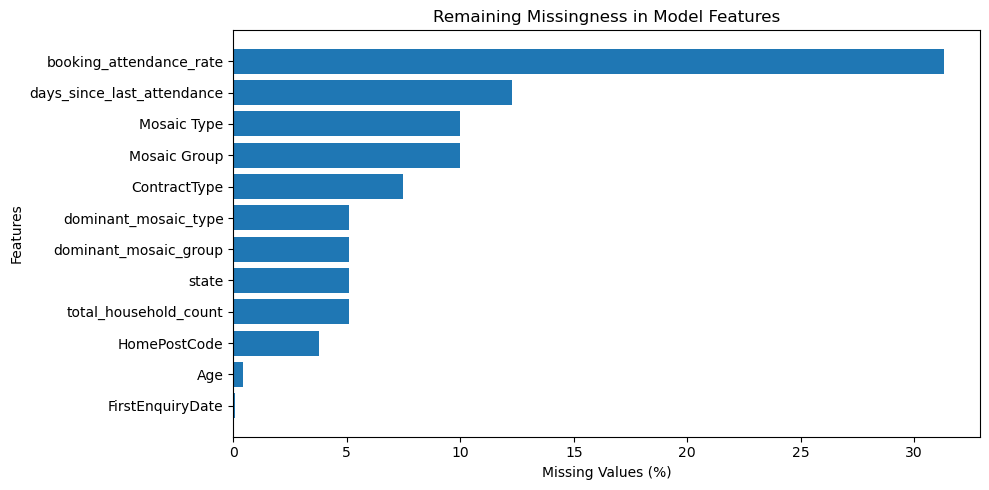

In [191]:
#missing values by feature
import matplotlib.pyplot as plt

# Exclude identifiers and target
exclude_cols = ['HashID', 'PrimaryID', 'revenue_next_730d']

# Calculate missing percentages
missing_pct = (
    train_data.drop(columns=exclude_cols, errors='ignore')
    .isnull().mean() * 100
)

missing_pct = missing_pct[missing_pct > 0].sort_values()

# Plot missing values
plt.figure(figsize=(10, 5))
plt.barh(missing_pct.index, missing_pct.values)

plt.title('Remaining Missingness in Model Features')
plt.xlabel('Missing Values (%)')
plt.ylabel('Features')

plt.tight_layout()
plt.savefig('data-1.png', dpi=300)
plt.show()

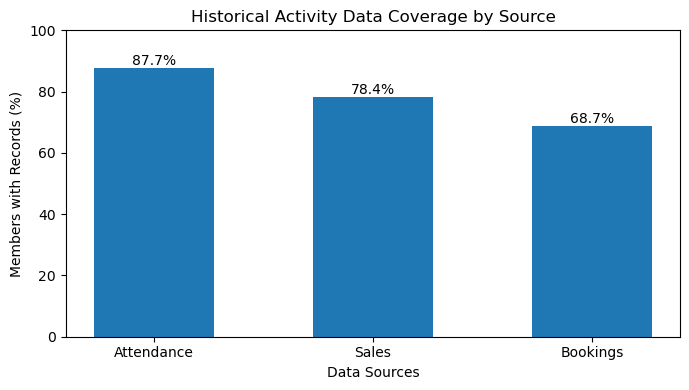

In [192]:
# Historical activity data coverage
coverage = {
    'Attendance': (train_data['attendance_count'].fillna(0) > 0).mean() * 100,
    'Sales': (train_data['sales_transactions'].fillna(0) > 0).mean() * 100,
    'Bookings': (
        (train_data['booking_count'].fillna(0) > 0) |
        (train_data['waitlist_count'].fillna(0) > 0)
    ).mean() * 100
}

# Plot data coverage
plt.figure(figsize=(7, 4))
bars = plt.bar(coverage.keys(), coverage.values(), width=0.55)

plt.title('Historical Activity Data Coverage by Source')
plt.xlabel('Data Sources')
plt.ylabel('Members with Records (%)')
plt.ylim(0, 100)

# Add percentage labels
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        f'{height:.1f}%',
        ha='center'
    )

plt.tight_layout()
plt.savefig('data-2.png', dpi=300)
plt.show()

In [193]:
# More feature engineering
import numpy as np
SEED = 0

# Feature Engineering: Spending behaviour
spending_cols = [
    'revenue_fb', 'revenue_other', 'revenue_pt',
    'revenue_swim', 'revenue_tennis'
]

# Number of categories with positive spending
model_data['spending_category_count'] = (
    model_data[spending_cols] > 0
).sum(axis=1)

# Share of historical revenue from F&B
model_data['fb_spending_share'] = (
    model_data['revenue_fb'] /
    model_data['historical_revenue'].where(
        model_data['historical_revenue'] > 0
    )
)

# Check engineered features
print(model_data[
    ['spending_category_count', 'fb_spending_share']
].describe())

print('\nMissing values:')
print(model_data[
    ['spending_category_count', 'fb_spending_share']
].isnull().sum())

print('\nF&B spending share outside [0, 1]:')
print((
    (model_data['fb_spending_share'] < 0) |
    (model_data['fb_spending_share'] > 1)
).sum())

       spending_category_count  fb_spending_share
count             13622.000000       10695.000000
mean                  0.981868           0.818394
std                   0.682488           0.356075
min                   0.000000           0.000000
25%                   1.000000           0.945023
50%                   1.000000           1.000000
75%                   1.000000           1.000000
max                   4.000000           1.000000

Missing values:
spending_category_count       0
fb_spending_share          2927
dtype: int64

F&B spending share outside [0, 1]:
0


In [194]:
# Feature Engineering: Spending intensity
model_data['spending_per_active_day'] = (
    model_data['historical_revenue'] /
    model_data['sales_active_days'].replace(0, np.nan)
)

# Check the new feature
print(model_data['spending_per_active_day'].describe())

print('\nMissing values:')
print(model_data['spending_per_active_day'].isnull().sum())

print('\nNegative values:')
print((model_data['spending_per_active_day'] < 0).sum())

count    10695.000000
mean        26.919948
std         55.477342
min          0.900000
25%          8.593228
50%         13.802206
75%         24.708020
max       1530.000000
Name: spending_per_active_day, dtype: float64

Missing values:
2927

Negative values:
0


In [195]:
#Attendance intensity

# Membership tenure in months
model_data['membership_tenure_months'] = (
    model_data['membership_tenure_days'] / 30.44
)

# Average monthly attendance
model_data['attendance_per_tenure_month'] = (
    model_data['attendance_count'] /
    model_data['membership_tenure_months'].clip(lower=1)
)

# Check the new feature
print(model_data['attendance_per_tenure_month'].describe())

print('\nMissing values:')
print(model_data['attendance_per_tenure_month'].isnull().sum())

print('\nNegative values:')
print((model_data['attendance_per_tenure_month'] < 0).sum())

count    13622.000000
mean         4.982244
std          7.407394
min          0.000000
25%          0.506045
50%          2.188957
75%          6.321814
max         87.460643
Name: attendance_per_tenure_month, dtype: float64

Missing values:
0

Negative values:
0


In [196]:
# Check members with highest monthly attendance
print(
    model_data[
        [
            'attendance_count',
            'membership_tenure_days',
            'membership_tenure_months',
            'attendance_per_tenure_month'
        ]
    ].sort_values(
        'attendance_per_tenure_month',
        ascending=False
    ).head(10)
)

       attendance_count  membership_tenure_days  membership_tenure_months  \
2632             1609.0                     560                 18.396846   
10522            1173.0                     415                 13.633377   
11114             951.0                     366                 12.023653   
9933             1038.0                     432                 14.191853   
10055             913.0                     395                 12.976347   
3712             1594.0                     701                 23.028909   
4002             1192.0                     560                 18.396846   
10449            1044.0                     500                 16.425756   
3581             1560.0                     750                 24.638633   
10151            1504.0                     730                 23.981603   

       attendance_per_tenure_month  
2632                     87.460643  
10522                    86.038843  
11114                    79.094098  
9933

In [197]:
# Feature Engineering: Monthly active attendance days
model_data['active_days_per_tenure_month'] = (
    model_data['active_days'] /
    model_data['membership_tenure_months'].clip(lower=1)
)

# Check the feature
print(model_data['active_days_per_tenure_month'].describe())

print('\nMissing values:')
print(model_data['active_days_per_tenure_month'].isnull().sum())

print('\nNegative values:')
print((model_data['active_days_per_tenure_month'] < 0).sum())

count    13622.000000
mean         3.090247
std          3.869385
min          0.000000
25%          0.380993
50%          1.588569
75%          4.342499
max         34.182623
Name: active_days_per_tenure_month, dtype: float64

Missing values:
0

Negative values:
0


In [198]:
# Check unusually high monthly active attendance days
high_active = model_data[
    model_data['active_days_per_tenure_month'] > 30.44
]

print('Members above 30.44 days/month:', len(high_active))

print(
    high_active[
        [
            'active_days',
            'membership_tenure_days',
            'membership_tenure_months',
            'active_days_per_tenure_month'
        ]
    ].sort_values(
        'active_days_per_tenure_month',
        ascending=False
    ).head(10)
)

Members above 30.44 days/month: 1
       active_days  membership_tenure_days  membership_tenure_months  \
11114        411.0                     366                 12.023653   

       active_days_per_tenure_month  
11114                     34.182623  


In [199]:
# Check the member with inconsistent attendance history
member_id = model_data.loc[10028, 'HashID']
join_date = model_data.loc[10028, 'JoinDate']

print('Join Date:', join_date)

member_attendance = attendance_clean[
    attendance_clean['HashID'] == member_id
].copy()

print(member_attendance.head())
print(member_attendance.columns.tolist())

Join Date: 2022-02-13 00:00:00
       SiteID                                             HashID  \
135098     MD  0x8E76EABB9AE8A1203F52353994A0946485617634B75C...   
135142     MD  0x8E76EABB9AE8A1203F52353994A0946485617634B75C...   
142340     MD  0x8E76EABB9AE8A1203F52353994A0946485617634B75C...   
142345     MD  0x8E76EABB9AE8A1203F52353994A0946485617634B75C...   
158838     MD  0x8E76EABB9AE8A1203F52353994A0946485617634B75C...   

                     ADateTime AttendanceDate  
135098 2022-08-31 17:58:21.760     2022-08-31  
135142 2022-08-31 18:03:37.150     2022-08-31  
142340 2022-09-02 18:58:03.340     2022-09-02  
142345 2022-09-02 19:01:51.603     2022-09-02  
158838 2022-09-07 18:39:04.003     2022-09-07  
['SiteID', 'HashID', 'ADateTime', 'AttendanceDate']


In [200]:
# Check attendance records before JoinDate
attendance_check = attendance_clean.merge(
    model_data[['HashID', 'JoinDate']],
    on='HashID',
    how='inner'
)

attendance_check['AttendanceDate'] = pd.to_datetime(
    attendance_check['AttendanceDate']
)

# Identify attendance before current JoinDate
before_join = attendance_check[
    attendance_check['AttendanceDate'] <
    attendance_check['JoinDate']
]

print('Attendance records before JoinDate:', len(before_join))
print('Members affected:', before_join['HashID'].nunique())
print('Percentage of members affected:',
      round(before_join['HashID'].nunique() / len(model_data) * 100, 2))

Attendance records before JoinDate: 4964
Members affected: 168
Percentage of members affected: 1.23


In [201]:
# Feature Engineering: Behavioural indicators

# Historical spending activity
model_data['has_historical_spending'] = (
    model_data['sales_transactions'].fillna(0) > 0
).astype(int)

# Attendance within 30 days before T0
model_data['has_recent_attendance'] = (
    model_data['days_since_last_attendance']
    .between(0, 30)
).astype(int)

# Future bookings already known at T0
model_data['has_known_future_booking'] = (
    model_data['future_bookings_known'].fillna(0) > 0
).astype(int)

# Check new features
new_features = [
    'has_historical_spending',
    'has_recent_attendance',
    'has_known_future_booking'
]

print(model_data[new_features].describe())

print('\nMissing values:')
print(model_data[new_features].isnull().sum())

print('\nPercentage of members with each indicator:')
print((model_data[new_features].mean() * 100).round(2))

       has_historical_spending  has_recent_attendance  \
count             13622.000000           13622.000000   
mean                  0.785127               0.628836   
std                   0.410749               0.483134   
min                   0.000000               0.000000   
25%                   1.000000               0.000000   
50%                   1.000000               1.000000   
75%                   1.000000               1.000000   
max                   1.000000               1.000000   

       has_known_future_booking  
count              13622.000000  
mean                   0.125312  
std                    0.331085  
min                    0.000000  
25%                    0.000000  
50%                    0.000000  
75%                    0.000000  
max                    1.000000  

Missing values:
has_historical_spending     0
has_recent_attendance       0
has_known_future_booking    0
dtype: int64

Percentage of members with each indicator:
has_historical_s

In [202]:
# Feature Engineering: Member behaviour segment

has_attendance = model_data['attendance_count'].fillna(0) > 0
has_spending = model_data['sales_transactions'].fillna(0) > 0

model_data['member_behaviour_segment'] = np.select(
    [
        ~has_attendance & ~has_spending,
        has_attendance & ~has_spending,
        ~has_attendance & has_spending,
        has_attendance & has_spending
    ],
    [
        'No Recorded Activity',
        'Attendance Only',
        'Spending Only',
        'Attendance and Spending'
    ],
    default='Unknown'
)

# Check distribution
print(model_data['member_behaviour_segment'].value_counts())

print('\nPercentage of members:')
print(
    model_data['member_behaviour_segment']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print('\nMissing values:')
print(model_data['member_behaviour_segment'].isnull().sum())

member_behaviour_segment
Attendance and Spending    9959
Attendance Only            1986
No Recorded Activity        941
Spending Only               736
Name: count, dtype: int64

Percentage of members:
member_behaviour_segment
Attendance and Spending    73.11
Attendance Only            14.58
No Recorded Activity        6.91
Spending Only               5.40
Name: proportion, dtype: float64

Missing values:
0


In [203]:
# Feature Engineering: Final validation

engineered_features = [
    'membership_tenure_days',
    'spending_category_count',
    'fb_spending_share',
    'spending_per_active_day',
    'has_historical_spending',
    'has_recent_attendance',
    'has_known_future_booking',
    'member_behaviour_segment'
]

# Check missing values
print('Missing values:')
print(model_data[engineered_features].isnull().sum())

# Check infinite values
numeric_features = model_data[engineered_features].select_dtypes(include='number')

print('\nInfinite values:')
print(np.isinf(numeric_features).sum())

# Check duplicate members
print('\nDuplicate HashID:', model_data['HashID'].duplicated().sum())

# Check dataset shape
print('\nDataset shape:', model_data.shape)

Missing values:
membership_tenure_days         0
spending_category_count        0
fb_spending_share           2927
spending_per_active_day     2927
has_historical_spending        0
has_recent_attendance          0
has_known_future_booking       0
member_behaviour_segment       0
dtype: int64

Infinite values:
membership_tenure_days      0
spending_category_count     0
fb_spending_share           0
spending_per_active_day     0
has_historical_spending     0
has_recent_attendance       0
has_known_future_booking    0
dtype: int64

Duplicate HashID: 0

Dataset shape: (13622, 55)


In [204]:
# Check MOSAIC feature distributions
mosaic_cols = [
    'Mosaic Group',
    'Mosaic Type',
    'dominant_mosaic_group',
    'dominant_mosaic_type'
]

for col in mosaic_cols:
    print(f'\n{col}')
    print('Unique categories:', model_data[col].nunique())
    print('Missing values:', model_data[col].isnull().sum())
    print('Categories with fewer than 30 members:',
          (model_data[col].value_counts() < 30).sum())
    print(model_data[col].value_counts().head(10))


Mosaic Group
Unique categories: 14
Missing values: 1364
Categories with fewer than 30 members: 1
Mosaic Group
A    4033
C    2064
B    1583
D    1387
I    1124
G     686
E     334
M     289
F     285
J     187
Name: count, dtype: int64

Mosaic Type
Unique categories: 52
Missing values: 1364
Categories with fewer than 30 members: 20
Mosaic Type
A01    1585
A02    1429
D12    1227
C10     887
I28     846
B05     784
C08     763
A04     682
B07     454
C09     414
Name: count, dtype: int64

dominant_mosaic_group
Unique categories: 14
Missing values: 685
Categories with fewer than 30 members: 3
dominant_mosaic_group
A    3919
G    2249
B    2203
C    1726
I    1591
D     355
J     329
F     215
E     144
M     118
Name: count, dtype: int64

dominant_mosaic_type
Unique categories: 48
Missing values: 685
Categories with fewer than 30 members: 25
dominant_mosaic_type
C10    1764
A01    1699
I28    1310
B05    1300
G21    1232
D12     968
B07     891
G22     673
A02     645
C08     332
Name: 

In [205]:
# Feature Engineering: MOSAIC categories

model_data['mosaic_group_clean'] = (
    model_data['Mosaic Group'].fillna('Unknown')
)

model_data['area_mosaic_group_clean'] = (
    model_data['dominant_mosaic_group'].fillna('Unknown')
)

# Check distributions
print(model_data['mosaic_group_clean'].value_counts())

print('\nArea MOSAIC Group:')
print(model_data['area_mosaic_group_clean'].value_counts())

print('\nMissing values:')
print(
    model_data[
        ['mosaic_group_clean', 'area_mosaic_group_clean']
    ].isnull().sum()
)

mosaic_group_clean
A          4033
C          2064
B          1583
D          1387
Unknown    1364
I          1124
G           686
E           334
M           289
F           285
J           187
N           142
H            86
K            30
L            28
Name: count, dtype: int64

Area MOSAIC Group:
area_mosaic_group_clean
A          3919
G          2249
B          2203
C          1726
I          1591
Unknown     685
D           355
J           329
F           215
E           144
M           118
H            31
L            25
K            25
N             7
Name: count, dtype: int64

Missing values:
mosaic_group_clean         0
area_mosaic_group_clean    0
dtype: int64


In [206]:
sample = pd.read_csv('sample_submission.csv')

print('Kaggle test members:', len(sample))
print('Unique test IDs:', sample['HashID'].nunique())

print('Overlap with train labels:',
      sample['HashID'].isin(train_labels['HashID']).sum())

print('Test IDs not found in members:',
      (~sample['HashID'].isin(members_clean['HashID'])).sum())

Kaggle test members: 1350
Unique test IDs: 1350
Overlap with train labels: 0
Test IDs not found in members: 0


In [207]:
print('Final shape:', model_data.shape)

print(
    'Train members:',
    model_data['revenue_next_730d'].notna().sum()
)

print(
    'Kaggle test members:',
    model_data['revenue_next_730d'].isna().sum()
)

print(
    'Duplicate HashID:',
    model_data['HashID'].duplicated().sum()
)

Final shape: (13622, 57)
Train members: 12272
Kaggle test members: 1350
Duplicate HashID: 0


In [208]:
# Feature Engineering: Member Role
# 0 = Primary Member, 1 = Linked Member

model_data['member_role'] = model_data['LinkInd'].copy()

# Check the new feature
print(model_data['member_role'].value_counts())
print('Updated shape:', model_data.shape)

member_role
0    9752
1    3870
Name: count, dtype: int64
Updated shape: (13622, 58)


In [209]:
#attendance_180d
print(attendance.columns.tolist())
print(attendance.head())

['SiteID', 'HashID', 'ADateTime']
  SiteID                                             HashID  \
0     DC  0x9C672C2164E01A90425F0682A77936E89B061E80F003...   
1     CB  0xCA7BFEE926232A0F0D5DCEBB27A4093CF8377B2F9F16...   
2     CB  0x452004B6505351439B5D66B72EAB53462ED76A91EAE0...   
3     CB  0x6E7745C2743ECACFC721B8440EEA259367E15FA4E4C8...   
4     CB  0xF81EBBDD4B001973A932E40842C72A9492EAF989B6DF...   

                ADateTime  
0 2022-07-21 04:58:47.800  
1 2022-07-21 05:00:08.917  
2 2022-07-21 05:00:09.860  
3 2022-07-21 05:00:13.677  
4 2022-07-21 05:00:16.107  


In [210]:
# Calculate attendance in the last 180 days

attendance_180 = attendance.copy()
attendance_180['ADateTime'] = pd.to_datetime(attendance_180['ADateTime'])

# Filter attendance records
attendance_180 = attendance_180[
    (attendance_180['ADateTime'] >= T0 - pd.Timedelta(days=180)) &
    (attendance_180['ADateTime'] <= T0)
]

# Count attendance records for each member
attendance_180 = (
    attendance_180.groupby('HashID')
    .size()
    .reset_index(name='attendance_180d')
)

# Add the new feature to model_data
model_data = model_data.merge(
    attendance_180,
    on='HashID',
    how='left',
    validate='one_to_one'
)

model_data['attendance_180d'] = model_data['attendance_180d'].fillna(0).astype(int)

print(model_data[['HashID', 'attendance_180d']].head())
print(model_data.shape)

                                              HashID  attendance_180d
0  0xC2AC23BEF21E16A3968EFC3EC928436F2F1DFD00B20A...              130
1  0xBC39C8DB3EE6066C2751987915D1403967DC149AC48F...               50
2  0x0AA92FCADB2F4DB2D33AAE81AB0BAF92A9F9EFD106AB...                6
3  0x0166B308374A9BFECBD065E1E14722BE67A37BDCC479...                0
4  0xE58105310295CD5CF20471D510064481CAE698E05A89...               99
(13622, 59)


In [211]:
print(model_data['attendance_180d'].describe())
print('Missing:', model_data['attendance_180d'].isna().sum())
print('Negative values:', (model_data['attendance_180d'] < 0).sum())

count    13622.000000
mean        50.359786
std         62.037467
min          0.000000
25%          3.000000
50%         30.000000
75%         74.000000
max        640.000000
Name: attendance_180d, dtype: float64
Missing: 0
Negative values: 0


In [212]:
# Check duplicate attendance records before T0
attendance_check = attendance.copy()
attendance_check['ADateTime'] = pd.to_datetime(attendance_check['ADateTime'])

attendance_check = attendance_check[
    (attendance_check['ADateTime'] >= T0 - pd.Timedelta(days=180)) &
    (attendance_check['ADateTime'] <= T0)
]

print(
    'Duplicate attendance records:',
    attendance_check.duplicated(
        subset=['HashID', 'SiteID', 'ADateTime']
    ).sum()
)

Duplicate attendance records: 0


In [213]:
#feature:revenue_730d
print(sales.columns.tolist())
print(sales.head())

['SiteID', 'HashID', 'SaleID', 'RaisedDate', 'DueDate', 'ProductID', 'ProductName', 'ProductCounter', 'Amount', 'Quantity', 'DepartmentName', 'DepartmentCategory']
  SiteID                                             HashID    SaleID  \
0     RY  0xDFC44F301C93EB113D30B75E16472D92F18BA5F62BD2...  25063955   
1     MD  0xC162055C2591736E3C5C8D5444F5FF17EEDB2E7412FA...  16944072   
2     MD  0x3F5710453194012F735E8356B0676BF95602544F065C...  16554005   
3     MD  0x163928B0689FAC3BEBA2B39A12BA4DC753C1B3BEEE48...  16991988   
4     CB  0xBFCE547216FF66B1E99781421F9729AE24E6EF2A4FEC...  63002619   

           RaisedDate    DueDate   ProductID        ProductName  \
0 2022-11-18 11:44:34 2022-11-18  RY22501931    Vegan Flapjacks   
1 2023-11-05 12:46:56 2023-11-05  MD29901634        Small Chips   
2 2022-12-03 13:38:06 2022-12-03   MD3150011    Coke Zero 600ml   
3 2023-12-20 12:45:55 2023-12-20   MD2300123     Quesadilla Foh   
4 2024-01-04 18:09:55 2024-01-04  CB30000288  Capital Coast Al

In [214]:
# Calculate historical revenue in the last 730 days
sales_730 = sales.copy()
sales_730['RaisedDate'] = pd.to_datetime(sales_730['RaisedDate'])
sales_730['Revenue'] = sales_730['Amount'] * sales_730['Quantity']

# Filter sales records before T0
sales_730 = sales_730[
    (sales_730['RaisedDate'] >= T0 - pd.Timedelta(days=730)) &
    (sales_730['RaisedDate'] <= T0)
]

# Calculate revenue for each member
revenue_730 = (
    sales_730.groupby('HashID')['Revenue']
    .sum()
    .reset_index(name='revenue_730d')
)

# Add the new feature to model_data
model_data = model_data.merge(
    revenue_730,
    on='HashID',
    how='left',
    validate='one_to_one'
)

model_data['revenue_730d'] = model_data['revenue_730d'].fillna(0)

print(model_data[['HashID', 'revenue_730d']].head())
print(model_data.shape)

                                              HashID  revenue_730d
0  0xC2AC23BEF21E16A3968EFC3EC928436F2F1DFD00B20A...       1356.55
1  0xBC39C8DB3EE6066C2751987915D1403967DC149AC48F...          4.50
2  0x0AA92FCADB2F4DB2D33AAE81AB0BAF92A9F9EFD106AB...         19.35
3  0x0166B308374A9BFECBD065E1E14722BE67A37BDCC479...          4.00
4  0xE58105310295CD5CF20471D510064481CAE698E05A89...       3679.00
(13622, 60)


In [215]:
print(model_data['revenue_730d'].describe())
print('Missing:', model_data['revenue_730d'].isna().sum())
print('Negative values:', (model_data['revenue_730d'] < 0).sum())

count    13622.000000
mean       537.994654
std       1224.377762
min          0.000000
25%          8.100000
50%        126.300000
75%        539.337500
max      35779.700000
Name: revenue_730d, dtype: float64
Missing: 0
Negative values: 0


In [216]:
#feature:recent_revenue_180d
# Calculate revenue in the last 180 days
sales_180 = sales_730[
    sales_730['RaisedDate'] >= T0 - pd.Timedelta(days=180)
].copy()

# Calculate recent revenue for each member
recent_revenue = (
    sales_180.groupby('HashID')['Revenue']
    .sum()
    .reset_index(name='recent_revenue_180d')
)

# Add the new feature to model_data
model_data = model_data.merge(
    recent_revenue,
    on='HashID',
    how='left',
    validate='one_to_one'
)

model_data['recent_revenue_180d'] = (
    model_data['recent_revenue_180d'].fillna(0)
)

print(model_data[['HashID', 'recent_revenue_180d']].head())
print(model_data.shape)

                                              HashID  recent_revenue_180d
0  0xC2AC23BEF21E16A3968EFC3EC928436F2F1DFD00B20A...                215.8
1  0xBC39C8DB3EE6066C2751987915D1403967DC149AC48F...                  0.0
2  0x0AA92FCADB2F4DB2D33AAE81AB0BAF92A9F9EFD106AB...                  0.0
3  0x0166B308374A9BFECBD065E1E14722BE67A37BDCC479...                  0.0
4  0xE58105310295CD5CF20471D510064481CAE698E05A89...                507.4
(13622, 61)


In [217]:
print(model_data['recent_revenue_180d'].describe())
print('Missing:', model_data['recent_revenue_180d'].isna().sum())
print('Negative values:', (model_data['recent_revenue_180d'] < 0).sum())

# Recent revenue should not exceed 730-day revenue
print(
    'Recent revenue > 730-day revenue:',
    (model_data['recent_revenue_180d'] > model_data['revenue_730d']).sum()
)

count    13622.000000
mean       137.224878
std        345.476245
min          0.000000
25%          0.000000
50%         13.550000
75%        120.350000
max       7892.350000
Name: recent_revenue_180d, dtype: float64
Missing: 0
Negative values: 0
Recent revenue > 730-day revenue: 0


In [218]:
#feature:sales_transaction_730
# Count unique sales transactions in the last 730 days
sales_transactions_730 = (
    sales_730.groupby('HashID')['SaleID']
    .nunique()
    .reset_index(name='sales_transactions_730d')
)

# Add the new feature to model_data
model_data = model_data.merge(
    sales_transactions_730,
    on='HashID',
    how='left',
    validate='one_to_one'
)

model_data['sales_transactions_730d'] = (
    model_data['sales_transactions_730d'].fillna(0).astype(int)
)

print(model_data[['HashID', 'sales_transactions_730d']].head())
print(model_data.shape)

                                              HashID  sales_transactions_730d
0  0xC2AC23BEF21E16A3968EFC3EC928436F2F1DFD00B20A...                      134
1  0xBC39C8DB3EE6066C2751987915D1403967DC149AC48F...                        1
2  0x0AA92FCADB2F4DB2D33AAE81AB0BAF92A9F9EFD106AB...                        3
3  0x0166B308374A9BFECBD065E1E14722BE67A37BDCC479...                        1
4  0xE58105310295CD5CF20471D510064481CAE698E05A89...                      160
(13622, 62)


In [219]:
print(model_data['sales_transactions_730d'].describe())
print('Missing:', model_data['sales_transactions_730d'].isna().sum())
print('Negative values:', (model_data['sales_transactions_730d'] < 0).sum())

count    13622.000000
mean        31.267141
std         61.181408
min          0.000000
25%          1.000000
50%          9.000000
75%         34.000000
max       1421.000000
Name: sales_transactions_730d, dtype: float64
Missing: 0
Negative values: 0


In [220]:
#feature:days_since_last_sale
#Calculate days since last sale
sales_recency = sales.copy()
sales_recency['RaisedDate'] = pd.to_datetime(sales_recency['RaisedDate'])

sales_recency = sales_recency[
    sales_recency['RaisedDate'] <= T0
]

last_sale = sales_recency.groupby('HashID')['RaisedDate'].max()

model_data['days_since_last_sale'] = (
    T0.normalize() -
    model_data['HashID'].map(last_sale).dt.normalize()
).dt.days

In [221]:
print(model_data.columns[
    model_data.columns.str.contains('days_since_last_sale')
].tolist())

print(model_data.shape)

['days_since_last_sale']
(13622, 63)


In [222]:
#feature:fb_spend_730d
# Calculate F&B spending in the last 730 days
fb_sales_730 = sales_730[
    sales_730['DepartmentCategory'] == 'F&B'
]

fb_spend_730 = (
    fb_sales_730.groupby('HashID')['Revenue']
    .sum()
)

# Add the new feature to model_data
model_data['fb_spend_730d'] = (
    model_data['HashID'].map(fb_spend_730).fillna(0)
)

print(model_data[['HashID', 'fb_spend_730d']].head())
print(model_data.shape)

                                              HashID  fb_spend_730d
0  0xC2AC23BEF21E16A3968EFC3EC928436F2F1DFD00B20A...        1356.55
1  0xBC39C8DB3EE6066C2751987915D1403967DC149AC48F...           4.50
2  0x0AA92FCADB2F4DB2D33AAE81AB0BAF92A9F9EFD106AB...          19.35
3  0x0166B308374A9BFECBD065E1E14722BE67A37BDCC479...           4.00
4  0xE58105310295CD5CF20471D510064481CAE698E05A89...        3679.00
(13622, 64)


In [223]:
print(model_data['fb_spend_730d'].describe())
print('Missing:', model_data['fb_spend_730d'].isna().sum())
print('Negative values:', (model_data['fb_spend_730d'] < 0).sum())

print(
    'F&B spending > total revenue:',
    (model_data['fb_spend_730d'] > model_data['revenue_730d']).sum()
)

count    13622.000000
mean       328.991880
std        774.974849
min          0.000000
25%          0.000000
50%         65.275000
75%        331.837500
max      35474.700000
Name: fb_spend_730d, dtype: float64
Missing: 0
Negative values: 0
F&B spending > total revenue: 0


In [224]:
#feature:booking_count_180d
print(bookings.columns.tolist())
print(bookings.head())

['SiteID', 'HashID', 'BookingName', 'BookingCategory', 'StartDateTime', 'BookedDateTime', 'AttendedInd', 'WaitingListInd', 'Waitlist/Booked', 'Price']
  SiteID                                             HashID  \
0     RY  0x217AC4C053B37427D4B3E6D7BB961E03B29E1319B9F0...   
1     RY  0x217AC4C053B37427D4B3E6D7BB961E03B29E1319B9F0...   
2     KP  0x37B218855140F31D1E13B28C3926B99A39CEDB3D03FF...   
3     KP  0x37B218855140F31D1E13B28C3926B99A39CEDB3D03FF...   
4     KP  0x8A66E8E24EE58918A3C9B7DDAB20708E98579D4A05DF...   

               BookingName     BookingCategory       StartDateTime  \
0              Inbody Scan  Deleted Activities 2021-10-10 09:45:00   
1  Personal Prog. Check-In  Deleted Activities 2021-10-10 10:00:00   
2                  Hiit 45         Next Cardio 2021-11-29 06:00:00   
3                  Hiit 45         Next Cardio 2021-12-03 06:00:00   
4                  Hiit 45         Next Cardio 2021-12-31 06:00:00   

       BookedDateTime  AttendedInd  WaitingListIn

In [225]:
# Calculate bookings in the last 180 days
bookings_180 = bookings_clean.copy()

bookings_180['BookedDateTime'] = pd.to_datetime(bookings_180['BookedDateTime'])
bookings_180['StartDateTime'] = pd.to_datetime(bookings_180['StartDateTime'])

# Filter bookings within the 180-day window
bookings_180 = bookings_180[
    (bookings_180['BookedDateTime'] <= T0) &
    (bookings_180['StartDateTime'] >= T0 - pd.Timedelta(days=180)) &
    (bookings_180['StartDateTime'] <= T0) &
    (bookings_180['Waitlist/Booked'] == 'Booked')
]

# Count booking records for each member
booking_count_180 = bookings_180.groupby('HashID').size()

# Add the feature to model_data
model_data['booking_count_180d'] = (
    model_data['HashID'].map(booking_count_180).fillna(0).astype(int)
)

print(model_data[['HashID', 'booking_count_180d']].head())
print(model_data.shape)

                                              HashID  booking_count_180d
0  0xC2AC23BEF21E16A3968EFC3EC928436F2F1DFD00B20A...                 129
1  0xBC39C8DB3EE6066C2751987915D1403967DC149AC48F...                   1
2  0x0AA92FCADB2F4DB2D33AAE81AB0BAF92A9F9EFD106AB...                   0
3  0x0166B308374A9BFECBD065E1E14722BE67A37BDCC479...                   0
4  0xE58105310295CD5CF20471D510064481CAE698E05A89...                  54
(13622, 65)


In [226]:
print(model_data['booking_count_180d'].describe())
print('Missing:', model_data['booking_count_180d'].isna().sum())
print('Negative values:', (model_data['booking_count_180d'] < 0).sum())

# Check booking records with creation dates after activity dates
print(
    'Booking date after event date:',
    (bookings_180['BookedDateTime'] > bookings_180['StartDateTime']).sum()
)

count    13622.000000
mean        12.585377
std         28.795138
min          0.000000
25%          0.000000
50%          0.000000
75%         11.000000
max        706.000000
Name: booking_count_180d, dtype: float64
Missing: 0
Negative values: 0
Booking date after event date: 7710


In [227]:
print(bookings['Waitlist/Booked'].value_counts(dropna=False))

Waitlist/Booked
Booked        683854
Waitlisted     15680
NaN             9515
Name: count, dtype: int64


In [228]:
# Check bookings created after event start
late_bookings = bookings_180[
    bookings_180['BookedDateTime'] > bookings_180['StartDateTime']
].copy()

late_bookings['delay_days'] = (
    late_bookings['BookedDateTime'] -
    late_bookings['StartDateTime']
).dt.total_seconds() / 86400

print(late_bookings['delay_days'].describe())

print(
    late_bookings[
        ['BookingName', 'BookingCategory',
         'StartDateTime', 'BookedDateTime', 'delay_days']
    ].head(10)
)

count    7710.000000
mean        1.271596
std         3.763177
min         0.000012
25%         0.032619
50%         0.073872
75%         0.891291
max        69.966100
Name: delay_days, dtype: float64
                BookingName    BookingCategory       StartDateTime  \
524112       P.T. 45 Minute  Personal Training 2024-01-22 05:30:00   
524113  P.T. 1 Hour - Stand  Personal Training 2024-01-22 05:30:00   
524114       P.T. 45 Minute  Personal Training 2024-01-22 05:30:00   
524146                 RPM™        Next Cardio 2024-01-22 06:00:00   
524187       P.T. 45 Minute  Personal Training 2024-01-22 06:15:00   
524191  P.T. 1 Hour - Stand  Personal Training 2024-01-22 06:30:00   
524192       P.T. 45 Minute  Personal Training 2024-01-22 06:30:00   
524211       P.T. 45 Minute  Personal Training 2024-01-22 07:30:00   
524212  P.T. 1 Hour - Stand  Personal Training 2024-01-22 07:30:00   
524214       P.T. 45 Minute  Personal Training 2024-01-22 07:45:00   

            BookedDateTime  

In [229]:
# Bookings created before the event starts
valid_bookings_180 = bookings_180[
    bookings_180['BookedDateTime'] <= bookings_180['StartDateTime']
]

# Compare booking counts
strict_count = valid_bookings_180.groupby('HashID').size()

booking_comparison = model_data[['HashID', 'booking_count_180d']].copy()

booking_comparison['strict_booking_count_180d'] = (
    booking_comparison['HashID'].map(strict_count).fillna(0).astype(int)
)

print(booking_comparison[
    ['booking_count_180d', 'strict_booking_count_180d']
].describe())

print(
    'Members affected:',
    (booking_comparison['booking_count_180d'] !=
     booking_comparison['strict_booking_count_180d']).sum()
)

print(
    'Records excluded:',
    len(bookings_180) - len(valid_bookings_180)
)

       booking_count_180d  strict_booking_count_180d
count        13622.000000               13622.000000
mean            12.585377                  12.019380
std             28.795138                  28.336436
min              0.000000                   0.000000
25%              0.000000                   0.000000
50%              0.000000                   0.000000
75%             11.000000                   9.000000
max            706.000000                 705.000000
Members affected: 1510
Records excluded: 7710


In [230]:
# Final training and Kaggle test datasets
train_data = model_data[
    model_data['HashID'].isin(train_labels['HashID'])
].copy()

test_data = model_data[
    model_data['HashID'].isin(sample['HashID'])
].copy()

print('Train:', train_data.shape)
print('Kaggle Test:', test_data.shape)

print('Missing train targets:',
      train_data['revenue_next_730d'].isna().sum())

print('Overlapping IDs:',
      train_data['HashID'].isin(test_data['HashID']).sum())

Train: (12272, 65)
Kaggle Test: (1350, 65)
Missing train targets: 0
Overlapping IDs: 0


In [231]:
# Check PrimaryID
print('PrimaryID exists:', 'PrimaryID' in train_data.columns)

if 'PrimaryID' in train_data.columns:
    print('Missing PrimaryID:', train_data['PrimaryID'].isna().sum())
    print('Sample PrimaryID:')
    print(train_data[['HashID', 'PrimaryID']].head(10))

PrimaryID exists: True
Missing PrimaryID: 8808
Sample PrimaryID:
                                               HashID PrimaryID
0   0xC2AC23BEF21E16A3968EFC3EC928436F2F1DFD00B20A...       NaN
1   0xBC39C8DB3EE6066C2751987915D1403967DC149AC48F...       NaN
2   0x0AA92FCADB2F4DB2D33AAE81AB0BAF92A9F9EFD106AB...       NaN
3   0x0166B308374A9BFECBD065E1E14722BE67A37BDCC479...       NaN
4   0xE58105310295CD5CF20471D510064481CAE698E05A89...       NaN
5   0x03621881B772362476DE9529230A298B7E480C6233F1...       NaN
6   0x70FEF329FB61BE4567396609FC563044D98403D87289...       NaN
8   0x62131F1B26F3F515A7EB3C5DEDE183D0262CBC8CEC4E...       NaN
9   0x04DB3425EBDE2DB76E575689A8D3AC4978BEA502260E...       NaN
10  0xA193A72A0FB4EFF382E852B623F8FFD4E11888107BC9...       NaN


In [232]:
# Check PrimaryID and household relationships
primary_id = train_data['PrimaryID'].astype('string').str.strip()
primary_id = primary_id.replace('', pd.NA)

print('Missing or blank PrimaryID:', primary_id.isna().sum())

linked_ids = primary_id.dropna()
print('Linked members:', len(linked_ids))
print('PrimaryID found in model_data:',
      linked_ids.isin(model_data['HashID']).sum())
print('PrimaryID not found in model_data:',
      (~linked_ids.isin(model_data['HashID'])).sum())

Missing or blank PrimaryID: 8808
Linked members: 3464
PrimaryID found in model_data: 3107
PrimaryID not found in model_data: 357


In [233]:
# Create HouseholdID
model_data['HashID'] = model_data['HashID'].astype('string').str.strip()
model_data['PrimaryID'] = model_data['PrimaryID'].astype('string').str.strip()
model_data['PrimaryID'] = model_data['PrimaryID'].replace('', pd.NA)

model_data['HouseholdID'] = model_data['PrimaryID'].fillna(model_data['HashID'])

# Update training and Kaggle test datasets
train_data = model_data[
    model_data['HashID'].isin(train_labels['HashID'])
].copy()

test_data = model_data[
    model_data['HashID'].isin(sample['HashID'])
].copy()

print('Unique households:', train_data['HouseholdID'].nunique())
print('Missing HouseholdID:', train_data['HouseholdID'].isna().sum())

Unique households: 9067
Missing HouseholdID: 0


In [234]:
from sklearn.model_selection import GroupShuffleSplit

# Household-aware train/validation split
gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=SEED
)

train_idx, val_idx = next(
    gss.split(train_data, groups=train_data['HouseholdID'])
)

train_set = train_data.iloc[train_idx].copy()
val_set = train_data.iloc[val_idx].copy()

# Check the results
print('Training set:', train_set.shape)
print('Validation set:', val_set.shape)

print('Overlapping households:',
      train_set['HouseholdID'].isin(val_set['HouseholdID']).sum())

Training set: (9835, 66)
Validation set: (2437, 66)
Overlapping households: 0


In [235]:
# Compare target distributions
for name, df in [('Training', train_set), ('Validation', val_set)]:
    y = df['revenue_next_730d']

    print('\n', name)
    print('Members:', len(df))
    print('Mean:', round(y.mean(), 2))
    print('Median:', round(y.median(), 2))
    print('Zero revenue (%):', round((y == 0).mean() * 100, 2))


 Training
Members: 9835
Mean: 475.55
Median: 47.6
Zero revenue (%): 34.08

 Validation
Members: 2437
Mean: 460.11
Median: 41.5
Zero revenue (%): 35.45


In [236]:
# Export complete processed dataset
final_data = model_data.copy()

# Save all features without dropping any columns
final_data.to_csv('processed_member_data.csv', index=False)

# Check the exported dataset
print(final_data.shape)
print(final_data.columns.tolist())

(13622, 66)
['SiteID', 'HashID', 'JoinDate', 'Age', 'Gender', 'TitleID', 'PrimaryInd', 'LinkInd', 'PrimaryID', 'MemberType', 'FirstEnquiryDate', 'HomePostCode', 'SubTypeID', 'SubDescription', 'PaymentMethodID', 'SubLevel1', 'SubLevel2', 'PaymentFreq', 'SubCategory', 'EnrolledInNextSteps', 'ContractType', 'total_household_count', 'state', 'dominant_mosaic_group', 'dominant_mosaic_type', 'Mosaic Group', 'Mosaic Type', 'revenue_next_730d', 'attendance_count', 'active_days', 'days_since_last_attendance', 'historical_revenue', 'sales_transactions', 'sales_active_days', 'revenue_fb', 'revenue_other', 'revenue_pt', 'revenue_swim', 'revenue_tennis', 'booking_count', 'attended_bookings', 'booking_attendance_rate', 'waitlist_count', 'future_bookings_known', 'membership_tenure_days', 'spending_category_count', 'fb_spending_share', 'spending_per_active_day', 'membership_tenure_months', 'attendance_per_tenure_month', 'active_days_per_tenure_month', 'has_historical_spending', 'has_recent_attendance'

In [237]:
# Select features for modelling
selected_features = [
    'Age',
    'membership_tenure_days',
    'member_role',
    'SubLevel1',
    'mosaic_group_clean',
    'days_since_last_attendance',
    'attendance_180d',
    'revenue_730d',
    'recent_revenue_180d',
    'sales_transactions_730d',
    'days_since_last_sale',
    'spending_category_count',
    'fb_spend_730d',
    'booking_count_180d'
]

# Create a new dataset with selected features
selected_data = model_data[
    ['HashID', 'HouseholdID']
    + selected_features
    + ['revenue_next_730d']
].copy()

# Save selected features dataset
selected_data.to_csv('selected_features_data.csv', index=False)

# Check the new dataset
print(selected_data.shape)
print(selected_data.columns.tolist())

(13622, 17)
['HashID', 'HouseholdID', 'Age', 'membership_tenure_days', 'member_role', 'SubLevel1', 'mosaic_group_clean', 'days_since_last_attendance', 'attendance_180d', 'revenue_730d', 'recent_revenue_180d', 'sales_transactions_730d', 'days_since_last_sale', 'spending_category_count', 'fb_spend_730d', 'booking_count_180d', 'revenue_next_730d']


In [238]:
#eda

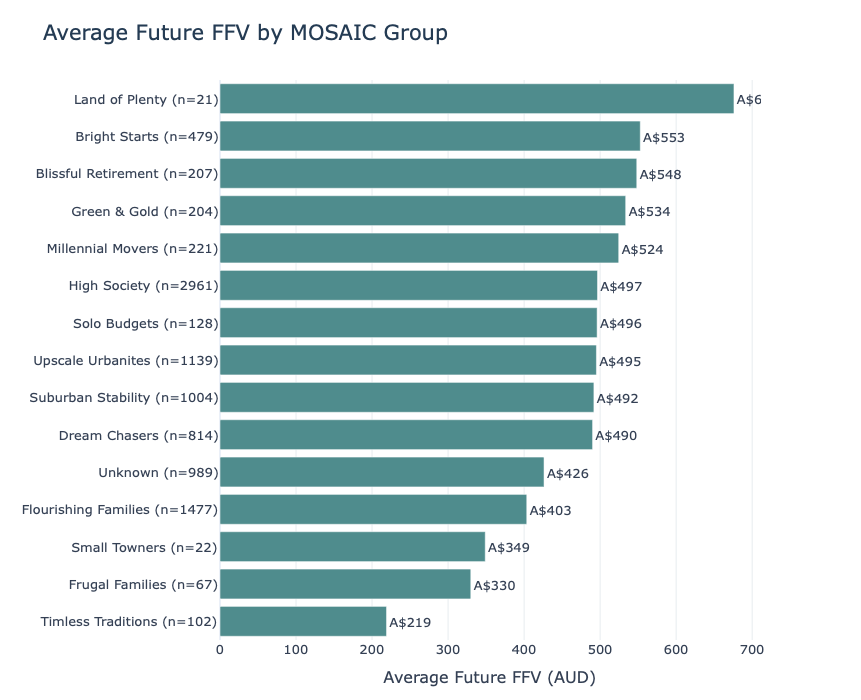

In [239]:
# MOSAIC Group names from the data dictionary
mosaic_names = {
    'A': 'High Society',
    'B': 'Upscale Urbanites',
    'C': 'Flourishing Families',
    'D': 'Suburban Stability',
    'E': 'Millennial Movers',
    'F': 'Green & Gold',
    'G': 'Bright Starts',
    'H': 'Frugal Families',
    'I': 'Dream Chasers',
    'J': 'Solo Budgets',
    'K': 'Small Towners',
    'L': 'Land of Plenty',
    'M': 'Blissful Retirement',
    'N': 'Timless Traditions',
    'Unknown': 'Unknown'
}

# Calculate average FFV and group size
mosaic_ffv = (
    train_set.groupby('mosaic_group_clean')['revenue_next_730d']
    .agg(['mean', 'count'])
    .reset_index()
    .sort_values('mean')
)

# Create labels with full group names and sample size
mosaic_ffv['group_label'] = (
    mosaic_ffv['mosaic_group_clean'].map(mosaic_names)
    + ' (n=' + mosaic_ffv['count'].astype(str) + ')'
)

# Plot
fig = px.bar(
    mosaic_ffv,
    x='mean',
    y='group_label',
    orientation='h',
    text='mean',
    title='Average Future FFV by MOSAIC Group'
)

fig.update_traces(
    marker_color='#4F8C8D',
    texttemplate='A$%{x:,.0f}',
    textposition='outside'
)

fig.update_layout(
    template='plotly_white',
    width=1100,
    height=700,
    showlegend=False,
    xaxis_title='Average Future FFV (AUD)',
    yaxis_title=None,
    xaxis=dict(showgrid=True, gridcolor='#E8EDF0'),
    margin=dict(l=220, r=100, t=80, b=60),
    font=dict(size=13, color='#344054'),
    title_font=dict(size=21, color='#243B53')
)

fig.update_layout(hovermode=False)

fig.show(config={
    'scrollZoom': False,
    'displayModeBar': True,
    'modeBarButtonsToRemove': [
        'zoom2d', 'pan2d', 'select2d',
        'lasso2d', 'zoomIn2d', 'zoomOut2d',
        'autoScale2d', 'resetScale2d'
    ]
})

In [240]:
# Step 1: Prepare features for VIF analysis

vif_features = [
    'Age',
    'membership_tenure_days',
    'member_role',
    'days_since_last_attendance',
    'attendance_180d',
    'revenue_730d',
    'recent_revenue_180d',
    'sales_transactions_730d',
    'days_since_last_sale',
    'spending_category_count',
    'fb_spend_730d',
    'booking_count_180d'
]

vif_data = train_set[vif_features].copy()

print(vif_data.shape)
print(vif_data.isnull().sum())

(9835, 12)
Age                             38
membership_tenure_days           0
member_role                      0
days_since_last_attendance    1203
attendance_180d                  0
revenue_730d                     0
recent_revenue_180d              0
sales_transactions_730d          0
days_since_last_sale          2145
spending_category_count          0
fb_spend_730d                    0
booking_count_180d               0
dtype: int64


In [241]:
# Step 2: Handle missing values for VIF

vif_clean = vif_data.copy()
vif_clean = vif_clean.fillna(vif_clean.median())

print('Remaining missing values:', vif_clean.isnull().sum().sum())

Remaining missing values: 0


In [242]:
# Step 3: Calculate VIF

import pandas as pd
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

X_vif = add_constant(vif_clean, has_constant='add')

vif_results = pd.DataFrame({
    'Feature': vif_features,
    'VIF': [
        variance_inflation_factor(X_vif.values, i)
        for i in range(1, X_vif.shape[1])
    ]
})

vif_results = vif_results.sort_values('VIF', ascending=False)

print(vif_results)

                       Feature       VIF
5                 revenue_730d  4.770677
6          recent_revenue_180d  4.106466
7      sales_transactions_730d  3.955319
10               fb_spend_730d  3.910648
0                          Age  1.952394
2                  member_role  1.691194
4              attendance_180d  1.437889
9      spending_category_count  1.410614
11          booking_count_180d  1.263852
1       membership_tenure_days  1.245225
8         days_since_last_sale  1.237160
3   days_since_last_attendance  1.181941


In [243]:
# Step 1: Spearman correlation with Future ffv

target = 'revenue_next_730d'

spearman_target = train_set[
    vif_features + [target]
].corr(method='spearman')[target].drop(target)

spearman_target = spearman_target.sort_values(
    key=abs, ascending=False
)

print(spearman_target.round(3))

recent_revenue_180d           0.713
sales_transactions_730d       0.700
revenue_730d                  0.683
fb_spend_730d                 0.616
days_since_last_sale         -0.611
spending_category_count       0.483
attendance_180d               0.410
booking_count_180d            0.377
days_since_last_attendance   -0.363
Age                           0.202
member_role                  -0.192
membership_tenure_days        0.116
Name: revenue_next_730d, dtype: float64


In [244]:
# Step 2: Spearman correlation between features

spearman_matrix = train_set[
    vif_features
].corr(method='spearman')

print(spearman_matrix.round(2))

                             Age  membership_tenure_days  member_role  \
Age                         1.00                    0.37        -0.55   
membership_tenure_days      0.37                    1.00        -0.10   
member_role                -0.55                   -0.10         1.00   
days_since_last_attendance -0.22                   -0.11         0.19   
attendance_180d             0.40                    0.08        -0.42   
revenue_730d                0.11                    0.01        -0.18   
recent_revenue_180d         0.16                    0.03        -0.19   
sales_transactions_730d     0.20                    0.06        -0.26   
days_since_last_sale       -0.19                   -0.11         0.15   
spending_category_count     0.06                   -0.07        -0.15   
fb_spend_730d               0.35                    0.08        -0.41   
booking_count_180d          0.10                   -0.03        -0.09   

                            days_since_last_attend

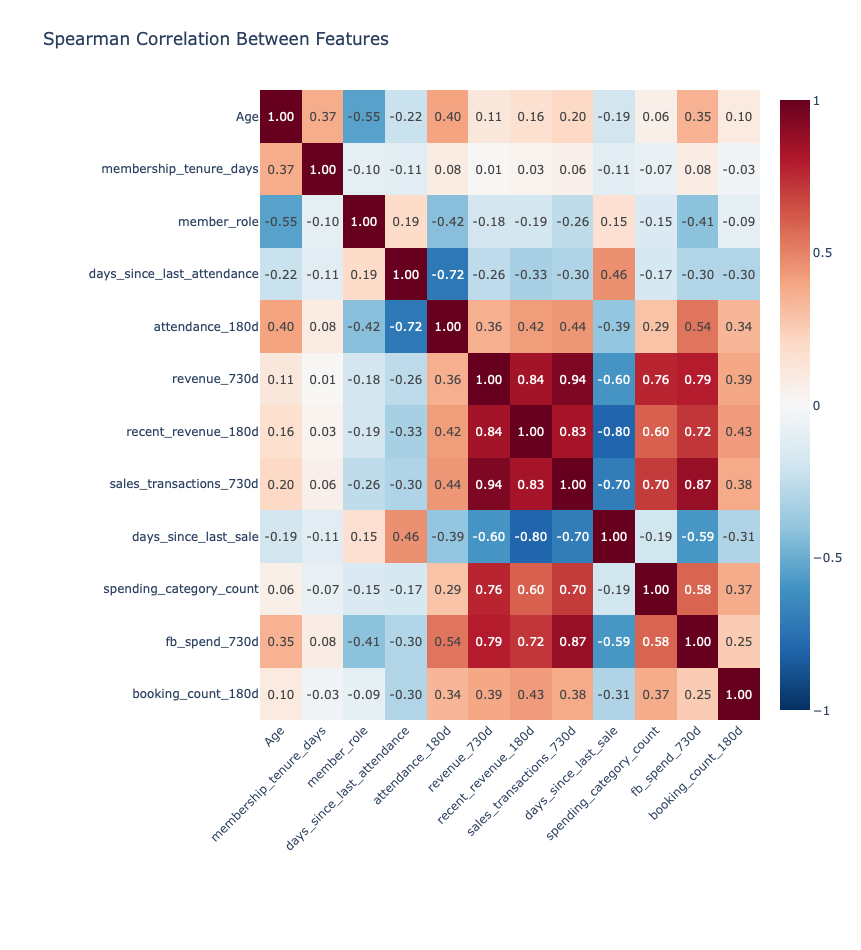

In [245]:
# Spearman correlation heatmap

import plotly.express as px

spearman_matrix = train_set[vif_features].corr(method='spearman')

fig = px.imshow(
    spearman_matrix,
    text_auto='.2f',
    color_continuous_scale='RdBu_r',
    zmin=-1,
    zmax=1,
    aspect='auto',
    title='Spearman Correlation Between Features'
)

fig.update_traces(
    hovertemplate=None,
    hoverinfo='skip'
)

fig.update_layout(
    width=1350,
    height=950,
    xaxis=dict(
        tickangle=-45,
        tickfont=dict(size=12)
    ),
    yaxis=dict(
        tickfont=dict(size=12)
    ),
    margin=dict(l=260, r=90, t=90, b=230),
    paper_bgcolor='white'
)

fig.show(config={
    'displayModeBar': True,
    'toImageButtonOptions': {
        'format': 'png',
        'filename': 'spearman_heatmap',
        'width': 1350,
        'height': 950,
        'scale': 2
    }
})

In [246]:
# Spearman correlation with Future ffv

target = 'revenue_next_730d'

spearman_target = train_set[
    vif_features + [target]
].corr(method='spearman')[target].drop(target)

spearman_target = spearman_target.sort_values(
    key=abs, ascending=False
)

print(spearman_target.round(3))

recent_revenue_180d           0.713
sales_transactions_730d       0.700
revenue_730d                  0.683
fb_spend_730d                 0.616
days_since_last_sale         -0.611
spending_category_count       0.483
attendance_180d               0.410
booking_count_180d            0.377
days_since_last_attendance   -0.363
Age                           0.202
member_role                  -0.192
membership_tenure_days        0.116
Name: revenue_next_730d, dtype: float64


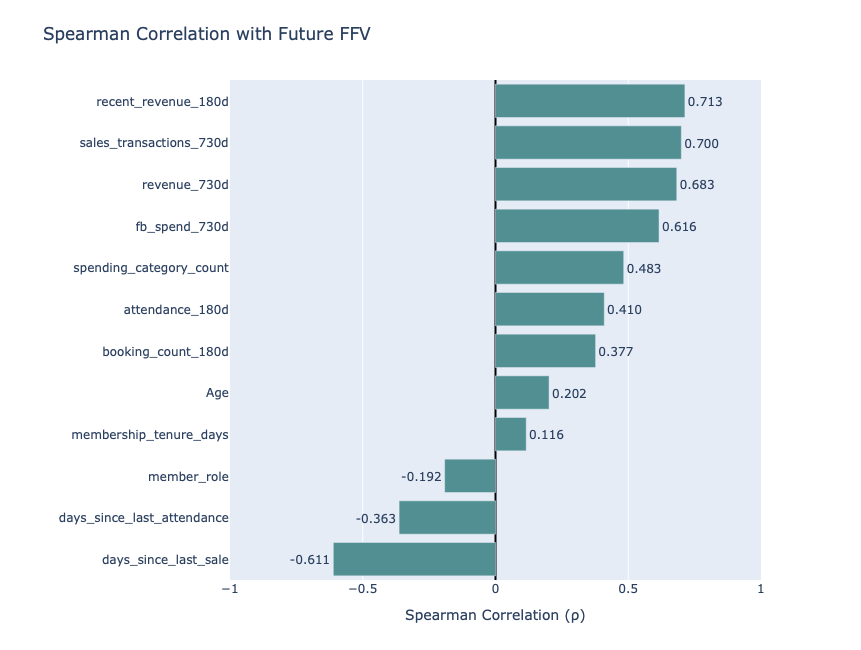

In [247]:
# Spearman correlation with Future ffv

target = 'revenue_next_730d'

spearman_target = train_set[
    vif_features + [target]
].corr(method='spearman')[target].drop(target)

spearman_target = spearman_target.sort_values()

# Plot Spearman correlation
import plotly.express as px

fig = px.bar(
    x=spearman_target.values,
    y=spearman_target.index,
    orientation='h',
    text=spearman_target.values,
    labels={
        'x': 'Spearman Correlation (ρ)',
        'y': 'Feature'
    },
    title='Spearman Correlation with Future FFV'
)

fig.update_traces(
    texttemplate='%{text:.3f}',
    textposition='outside',
    marker_color='#518F92'
)

fig.update_layout(
    width=1100,
    height=650,
    xaxis=dict(
        range=[-1, 1],
        zeroline=True,
        zerolinecolor='black'
    ),
    yaxis_title=None,
    margin=dict(l=230, r=100, t=80, b=70)
)

fig.show(config={
    'displayModeBar': True,
    'toImageButtonOptions': {
        'format': 'png',
        'filename': 'spearman_ffv',
        'width': 1200,
        'height': 750,
        'scale': 3
    }
})

In [248]:
# Check categorical features
categorical_features = ['SubLevel1', 'mosaic_group_clean']

for col in categorical_features:
    print(f'\nFeature: {col}')
    print('Missing values:', train_set[col].isna().sum())
    print('Unique categories:', train_set[col].nunique(dropna=False))
    print(train_set[col].value_counts(dropna=False))


Feature: SubLevel1
Missing values: 0
Unique categories: 3
SubLevel1
Silver/Fitness    6879
Gold/Premium      2946
Platinum            10
Name: count, dtype: int64

Feature: mosaic_group_clean
Missing values: 0
Unique categories: 15
mosaic_group_clean
A          2961
C          1477
B          1139
D          1004
Unknown     989
I           814
G           479
E           221
M           207
F           204
J           128
N           102
H            67
K            22
L            21
Name: count, dtype: int64


In [249]:
# Compare categorical features with future ffv
for col in categorical_features:
    print(f'\nFeature: {col}')

    summary = (
        train_set.groupby(col, dropna=False)['revenue_next_730d']
        .agg(['count', 'median', 'mean'])
        .sort_values('median', ascending=False)
    )

    print(summary)


Feature: SubLevel1
                count  median        mean
SubLevel1                                
Gold/Premium     2946  89.125  551.798676
Silver/Fitness   6879  34.450  443.459690
Platinum           10   0.000   87.030000

Feature: mosaic_group_clean
                    count   median        mean
mosaic_group_clean                            
L                      21  115.700  676.005714
I                     814   91.100  490.041499
F                     204   89.350  533.585539
E                     221   65.550  524.415113
H                      67   64.400  329.850149
M                     207   60.000  548.176280
G                     479   56.950  552.788058
B                    1139   51.300  495.106400
A                    2961   50.400  496.529591
D                    1004   47.475  491.779950
C                    1477   35.450  403.474577
K                      22   26.600  348.862727
J                     128   25.900  496.013359
Unknown               989   19.400  

In [250]:
# Check Revenue calculation
print(sales_730[['Amount', 'Quantity', 'Revenue']].head(10))

print('Quantity > 1:',
      (sales_730['Quantity'] > 1).sum())

print('Revenue calculation correct:',
      ((sales_730['Amount'] * sales_730['Quantity'] - sales_730['Revenue']).abs() < 1e-6).all())

   Amount  Quantity  Revenue
0    3.60         1     3.60
1    7.00         1     7.00
2    4.55         1     4.55
3    8.30         1     8.30
4    8.30         1     8.30
5    4.15         1     4.15
6   22.50         1    22.50
7    4.05         1     4.05
8    4.05         1     4.05
9   19.00         1    19.00
Quantity > 1: 1169
Revenue calculation correct: True


In [251]:
# Check merged revenue_730d
revenue_check = sales_730.groupby('HashID')['Revenue'].sum()

expected = model_data['HashID'].map(revenue_check).fillna(0)

print('Revenue mismatches:',
      ((model_data['revenue_730d'] - expected).abs() > 1e-6).sum())

Revenue mismatches: 0


In [252]:
# Check recent revenue
recent_check = sales_180.groupby('HashID')['Revenue'].sum()
expected_recent = model_data['HashID'].map(recent_check).fillna(0)

print('Recent revenue mismatches:',
      ((model_data['recent_revenue_180d'] - expected_recent).abs() > 1e-6).sum())

# Check F&B spending
fb_check = sales_730[
    sales_730['DepartmentCategory'] == 'F&B'
].groupby('HashID')['Revenue'].sum()

expected_fb = model_data['HashID'].map(fb_check).fillna(0)

print('F&B spending mismatches:',
      ((model_data['fb_spend_730d'] - expected_fb).abs() > 1e-6).sum())

Recent revenue mismatches: 0
F&B spending mismatches: 0


In [253]:
#EDA

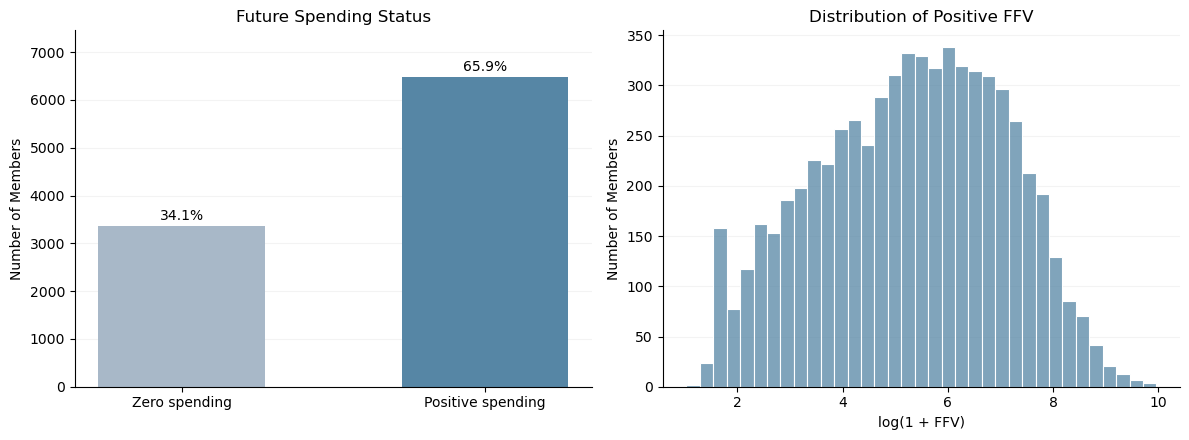

In [254]:
#1.target distribution
target = 'revenue_next_730d'

ffv = train_set[target].dropna()
positive_ffv = ffv[ffv > 0]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Zero vs positive ffv
counts = [(ffv == 0).sum(), (ffv > 0).sum()]
labels = ['Zero spending', 'Positive spending']

bars = axes[0].bar(labels, counts, color=['#A8B8C8', '#5686A5'], width=0.55)

for bar, count in zip(bars, counts):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + max(counts) * 0.02,
        f'{count / len(ffv):.1%}',
        ha='center'
    )

axes[0].set_title('Future Spending Status')
axes[0].set_ylabel('Number of Members')
axes[0].set_ylim(0, max(counts) * 1.15)

# Positive ffv distribution
sns.histplot(
    np.log1p(positive_ffv),
    bins=35,
    color='#5686A5',
    edgecolor='white',
    ax=axes[1]
)

axes[1].set_title('Distribution of Positive FFV')
axes[1].set_xlabel('log(1 + FFV)')
axes[1].set_ylabel('Number of Members')

for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='y', alpha=0.15)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig('target distribution.png')
plt.show()

In [255]:
from sklearn.model_selection import GroupKFold

# 1. Keep selected features and identifiers
export_cols = (
    ['HashID', 'HouseholdID']
    + selected_features
    + ['revenue_next_730d']
)

train_export = train_set[export_cols].copy().reset_index(drop=True)
val_export = val_set[export_cols].copy().reset_index(drop=True)
test_export = test_data[export_cols].copy().reset_index(drop=True)

# 2. Create the same 5 folds for everyone
# Members from the same household stay in the same fold
group_cv = GroupKFold(n_splits=5)

train_export['cv_fold'] = -1

for fold, (_, fold_val_idx) in enumerate(
    group_cv.split(
        train_export[selected_features],
        train_export['revenue_next_730d'],
        groups=train_export['HouseholdID']
    )
):
    train_export.loc[fold_val_idx, 'cv_fold'] = fold

# 3. Check fold quality
assert train_export['cv_fold'].between(0, 4).all()

assert (
    train_export.groupby('HouseholdID')['cv_fold'].nunique() == 1
).all()

assert set(train_export['HouseholdID']).isdisjoint(
    val_export['HouseholdID']
)

assert train_export['revenue_next_730d'].notna().all()
assert val_export['revenue_next_730d'].notna().all()

print('Training fold summary:')
print(
    train_export.groupby('cv_fold').agg(
        members=('HashID', 'size'),
        households=('HouseholdID', 'nunique'),
        mean_revenue=('revenue_next_730d', 'mean'),
        zero_revenue_pct=(
            'revenue_next_730d',
            lambda y: (y == 0).mean() * 100
        )
    ).round(2)
)

# 4. Export shared datasets
train_export.to_csv('nextgen_train_5fold.csv', index=False)
val_export.to_csv('nextgen_validation.csv', index=False)
test_export.to_csv('nextgen_kaggle_test.csv', index=False)

print('\nExported:')
print('Training:', train_export.shape)
print('Validation:', val_export.shape)
print('Kaggle test:', test_export.shape)

Training fold summary:
         members  households  mean_revenue  zero_revenue_pct
cv_fold                                                     
0           1967        1450        432.51             34.77
1           1967        1450        462.27             34.67
2           1967        1451        478.21             34.21
3           1967        1451        506.18             32.89
4           1967        1451        498.58             33.86

Exported:
Training: (9835, 18)
Validation: (2437, 17)
Kaggle test: (1350, 17)


In [256]:
# Shared preparation before modelling — run once

from sklearn.model_selection import PredefinedSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 1. Prepare shared model inputs
target = 'revenue_next_730d'

X_train = train_export[selected_features].copy()
y_train = train_export[target].copy()

X_val = val_export[selected_features].copy()
y_val = val_export[target].copy()

X_kaggle = test_export[selected_features].copy()

# 2. Reuse the fixed 5 folds
cv = PredefinedSplit(
    test_fold=train_export['cv_fold'].to_numpy()
)

# 3. Define feature types
categorical_features = [
    'SubLevel1',
    'mosaic_group_clean'
]

numeric_features = [
    col for col in selected_features
    if col not in categorical_features
]

# 4. Numeric preprocessing template
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(
        strategy='median',
        add_indicator=True
    )),
    ('scaler', StandardScaler())
])

# 5. Categorical preprocessing template
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(
        strategy='constant',
        fill_value='Unknown'
    )),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ))
])

# 6. Shared preprocessing template
preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_features),
    ('categorical', categorical_pipeline, categorical_features)
])

# 7. Check shared inputs
assert y_train.notna().all()
assert y_val.notna().all()

print('Training:', X_train.shape)
print('Validation:', X_val.shape)
print('Kaggle test:', X_kaggle.shape)
print('Number of folds:', cv.get_n_splits())
print('Shared preparation complete.')

Training: (9835, 14)
Validation: (2437, 14)
Kaggle test: (1350, 14)
Number of folds: 5
Shared preparation complete.


In [257]:
# Shared evaluation metrics: RMSLE and RMSE
import numpy as np
from sklearn.metrics import make_scorer

# Use the same prediction rule for both metrics
def prepare_predictions(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float).reshape(-1)
    y_pred = np.asarray(y_pred, dtype=float).reshape(-1)

    if y_true.shape != y_pred.shape:
        raise ValueError('Target and prediction lengths do not match.')

    if not np.isfinite(y_true).all() or not np.isfinite(y_pred).all():
        raise ValueError('Target or predictions contain NaN or infinity.')

    if (y_true < 0).any():
        raise ValueError('Revenue targets must be non-negative.')

    # Revenue predictions cannot be negative
    y_pred = np.clip(y_pred, 0, None)

    return y_true, y_pred


def evaluate_rmsle(y_true, y_pred):
    y_true, y_pred = prepare_predictions(y_true, y_pred)

    return np.sqrt(
        np.mean((np.log1p(y_true) - np.log1p(y_pred)) ** 2)
    )


def evaluate_rmse(y_true, y_pred):
    y_true, y_pred = prepare_predictions(y_true, y_pred)

    return np.sqrt(
        np.mean((y_true - y_pred) ** 2)
    )


# Shared scorers for cross-validation
scoring = {
    'RMSLE': make_scorer(evaluate_rmsle, greater_is_better=False),
    'RMSE': make_scorer(evaluate_rmse, greater_is_better=False)
}

print('Shared metrics ready: RMSLE and RMSE')

Shared metrics ready: RMSLE and RMSE


In [258]:
import time
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import cross_validate

# =========================================================
# 1. Build baseline and linear models
# =========================================================

# Use a reference category for OLS.
linear_preprocessor = clone(preprocessor)
linear_preprocessor.set_params(
    categorical__encoder__drop="first"
)

def make_ols_pipeline():
    return Pipeline([
        ("preprocessor", clone(linear_preprocessor)),
        ("model", LinearRegression())
    ])


models = {
    "Mean baseline": DummyRegressor(strategy="mean"),

    "Median baseline": DummyRegressor(strategy="median"),

    "OLS": make_ols_pipeline(),

    "Log-target OLS": TransformedTargetRegressor(
        regressor=make_ols_pipeline(),
        func=np.log1p,
        inverse_func=np.expm1
    )
}

# =========================================================
# 2. Check shared inputs and fixed folds
# =========================================================

assert X_train.columns.tolist() == selected_features
assert X_val.columns.tolist() == selected_features

assert len(X_train) == len(y_train) == len(train_export)
assert len(X_val) == len(y_val) == len(val_export)

assert np.array_equal(
    cv.test_fold,
    train_export["cv_fold"].to_numpy()
)

assert (
    train_export.groupby("HouseholdID")["cv_fold"].nunique() == 1
).all()

assert set(train_export["HouseholdID"]).isdisjoint(
    val_export["HouseholdID"]
)

assert np.isfinite(y_train.to_numpy(dtype=float)).all()
assert np.isfinite(y_val.to_numpy(dtype=float)).all()

assert (y_train >= 0).all()
assert (y_val >= 0).all()

# =========================================================
# 3. Shared evaluation function
# =========================================================

def evaluate_model(model_name, estimator):
    """
    Uses the existing:
        X_train, y_train, X_val, y_val
        cv, scoring
        evaluate_rmse(), evaluate_rmsle()

    Gap = Val RMSE - Train RMSE.
    Training time includes preprocessing and one full fit.
    """

    # Fixed household-aware 5-fold CV.
    # Pipeline preprocessing is fitted separately in each fold.
    cv_result = cross_validate(
        estimator=clone(estimator),
        X=X_train,
        y=y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
        error_score="raise"
    )

    # Convert sklearn negative error scores to positive errors.
    cv_rmse = -cv_result["test_RMSE"]
    cv_rmsle = -cv_result["test_RMSLE"]

    # Fit on the complete training set.
    fitted_model = clone(estimator)

    start = time.perf_counter()
    fitted_model.fit(X_train, y_train)
    training_time = time.perf_counter() - start

    train_pred = fitted_model.predict(X_train)
    val_pred = fitted_model.predict(X_val)

    # Existing metric functions clip negative predictions to zero.
    # Log-target OLS automatically returns predictions in dollars.
    train_rmse = evaluate_rmse(y_train, train_pred)
    val_rmse = evaluate_rmse(y_val, val_pred)
    val_rmsle = evaluate_rmsle(y_val, val_pred)

    result = {
        "Model": model_name,
        "Train_RMSE": train_rmse,
        "Val_RMSE": val_rmse,
        "Val_RMSLE": val_rmsle,
        "Gap": val_rmse - train_rmse,
        "CV_RMSE_mean": cv_rmse.mean(),
        "CV_RMSE_SD": cv_rmse.std(ddof=1),
        "CV_RMSLE_mean": cv_rmsle.mean(),
        "CV_RMSLE_SD": cv_rmsle.std(ddof=1),
        "Training_time_s": training_time
    }

    fold_results = pd.DataFrame({
        "Model": model_name,
        "cv_fold": np.arange(cv.get_n_splits()),
        "RMSE": cv_rmse,
        "RMSLE": cv_rmsle,
        "Fit_time_s": cv_result["fit_time"]
    })

    return result, fitted_model, fold_results

# =========================================================
# 4. Run the four models
# =========================================================

results = []
fitted_models = {}
fold_tables = []

for model_name, estimator in models.items():
    print(f"Running: {model_name}")

    result, fitted_model, fold_results = evaluate_model(
        model_name,
        estimator
    )

    results.append(result)
    fitted_models[model_name] = fitted_model
    fold_tables.append(fold_results)

# =========================================================
# 5. Build and export the comparison table
# =========================================================

comparison_table = pd.DataFrame(results)

cv_fold_results = pd.concat(
    fold_tables,
    ignore_index=True
)

# Formatted display; exported table keeps numeric values.
comparison_display = comparison_table.copy()

comparison_display["CV RMSE mean ± SD"] = (
    comparison_table["CV_RMSE_mean"].map("{:.2f}".format)
    + " ± "
    + comparison_table["CV_RMSE_SD"].map("{:.2f}".format)
)

comparison_display["CV RMSLE mean ± SD"] = (
    comparison_table["CV_RMSLE_mean"].map("{:.3f}".format)
    + " ± "
    + comparison_table["CV_RMSLE_SD"].map("{:.3f}".format)
)

display_columns = [
    "Model",
    "Train_RMSE",
    "Val_RMSE",
    "Val_RMSLE",
    "Gap",
    "CV RMSE mean ± SD",
    "CV RMSLE mean ± SD",
    "Training_time_s"
]

display(comparison_display[display_columns].round(3))

comparison_table.to_csv(
    "baseline_linear_comparison.csv",
    index=False
)

cv_fold_results.to_csv(
    "baseline_linear_cv_folds.csv",
    index=False
)

# Shared result-table template for other models.
pd.DataFrame(columns=comparison_table.columns).to_csv(
    "model_comparison_template.csv",
    index=False
)

print("Saved:")
print("baseline_linear_comparison.csv")
print("baseline_linear_cv_folds.csv")
print("model_comparison_template.csv")

Running: Mean baseline
Running: Median baseline
Running: OLS
Running: Log-target OLS


,Model,Train_RMSE,Val_RMSE,Val_RMSLE,Gap,CV RMSE mean ± SD,CV RMSLE mean ± SD,Training_time_s
0,Mean baseline,1189.675,1194.784,4.001,5.108,1188.16 ± 70.70,3.948 ± 0.050,0.000
1,Median baseline,1264.305,1263.897,2.937,-0.409,1262.57 ± 74.44,2.922 ± 0.010,0.000
2,OLS,790.351,788.821,2.801,-1.530,796.00 ± 37.47,2.770 ± 0.017,0.023
3,Log-target OLS,105239.599,7657499.287,1.986,7552259.688,96009.18 ± 115043.01,2.020 ± 0.030,0.017


Saved:
baseline_linear_comparison.csv
baseline_linear_cv_folds.csv
model_comparison_template.csv


In [259]:
# Diagnose extreme predictions from Log-target OLS

log_ols = fitted_models["Log-target OLS"]

train_pred_logols = log_ols.predict(X_train)
val_pred_logols = log_ols.predict(X_val)

print("Train prediction quantiles:")
print(
    pd.Series(train_pred_logols).quantile(
        [0, 0.5, 0.9, 0.95, 0.99, 0.999, 1]
    )
)

print("\nValidation prediction quantiles:")
print(
    pd.Series(val_pred_logols).quantile(
        [0, 0.5, 0.9, 0.95, 0.99, 0.999, 1]
    )
)

print("\nMaximum actual validation FFV:")
print(y_val.max())

print("\nMaximum predicted validation FFV:")
print(np.max(val_pred_logols))

Train prediction quantiles:
0.000   -7.362799e-01
0.500    4.502203e+01
0.900    3.310232e+02
0.950    8.019061e+02
0.990    6.448889e+03
0.999    3.759731e+05
1.000    8.760756e+06
dtype: float64

Validation prediction quantiles:
0.000   -4.321875e-01
0.500    4.627439e+01
0.900    3.349176e+02
0.950    8.131109e+02
0.990    1.110066e+04
0.999    1.108153e+06
1.000    3.778540e+08
dtype: float64

Maximum actual validation FFV:
20756.1

Maximum predicted validation FFV:
377853982.0927219


In [260]:
val_diag = X_val.copy()

val_diag['Actual_FFV'] = y_val.values
val_diag['Predicted_FFV'] = val_pred_logols

val_diag['Absolute_Error'] = abs(
    val_diag['Actual_FFV'] - val_diag['Predicted_FFV']
)

val_diag.sort_values(
    'Predicted_FFV',
    ascending=False
).head(10)

,Age,membership_tenure_days,member_role,SubLevel1,mosaic_group_clean,days_since_last_attendance,attendance_180d,revenue_730d,recent_revenue_180d,sales_transactions_730d,days_since_last_sale,spending_category_count,fb_spend_730d,booking_count_180d,Actual_FFV,Predicted_FFV,Absolute_Error
866,55.0,5863,0,Gold/Premium,A,21.0,94,18625.65,3024.90,1078,0.0,2,17953.45,35,5332.25,3.778540e+08,3.778486e+08
60,53.0,775,0,Gold/Premium,G,12.0,94,17558.55,6561.05,297,10.0,3,2072.55,99,10479.65,1.125957e+07,1.124909e+07
836,50.0,6259,0,Silver/Fitness,B,14.0,179,9648.16,2532.41,613,15.0,2,9601.96,1,7133.25,1.651023e+06,1.643890e+06
1834,56.0,562,0,Gold/Premium,A,4.0,228,16699.24,5229.14,99,11.0,2,690.15,67,20756.10,4.059081e+05,3.851520e+05
161,74.0,2673,0,Gold/Premium,A,0.0,179,9486.50,1315.65,452,0.0,1,9486.50,135,9552.52,2.168458e+05,2.072932e+05
1674,62.0,2426,0,Gold/Premium,A,1.0,141,8853.04,2011.99,393,2.0,1,8853.04,13,9396.89,1.699872e+05,1.605903e+05
609,38.0,805,0,Silver/Fitness,B,66.0,9,11137.16,2541.96,383,0.0,3,5164.46,82,8004.75,1.120602e+05,1.040555e+05
1296,59.0,8943,0,Gold/Premium,A,0.0,287,6259.30,1513.25,360,0.0,1,6259.30,0,6136.65,6.475457e+04,5.861792e+04
2244,71.0,1239,0,Silver/Fitness,C,1.0,160,5728.85,2851.00,195,1.0,2,2697.65,65,2476.15,4.887109e+04,4.639494e+04
1264,79.0,9063,0,Silver/Fitness,D,1.0,217,4827.00,1361.75,421,8.0,2,4808.00,24,2942.00,4.805167e+04,4.510967e+04


In [261]:
log_pred = np.log1p(val_pred_logols)

print(
    pd.Series(log_pred).quantile(
        [0.5, 0.9, 0.95, 0.99, 0.999, 1]
    )
)

0.500     3.855969
0.900     5.816861
0.950     6.702097
0.990     9.314787
0.999    13.705189
1.000    19.750018
dtype: float64


In [262]:
# Check categorical features
categorical_features = ['SubLevel1', 'mosaic_group_clean']

for col in categorical_features:
    print(f'\nFeature: {col}')
    print('Missing values:', train_set[col].isna().sum())
    print('Unique categories:', train_set[col].nunique(dropna=False))
    print(train_set[col].value_counts(dropna=False))


Feature: SubLevel1
Missing values: 0
Unique categories: 3
SubLevel1
Silver/Fitness    6879
Gold/Premium      2946
Platinum            10
Name: count, dtype: int64

Feature: mosaic_group_clean
Missing values: 0
Unique categories: 15
mosaic_group_clean
A          2961
C          1477
B          1139
D          1004
Unknown     989
I           814
G           479
E           221
M           207
F           204
J           128
N           102
H            67
K            22
L            21
Name: count, dtype: int64


In [263]:
# Compare categorical features with future ffv
for col in categorical_features:
    print(f'\nFeature: {col}')

    summary = (
        train_set.groupby(col, dropna=False)['revenue_next_730d']
        .agg(['count', 'median', 'mean'])
        .sort_values('median', ascending=False)
    )

    print(summary)


Feature: SubLevel1
                count  median        mean
SubLevel1                                
Gold/Premium     2946  89.125  551.798676
Silver/Fitness   6879  34.450  443.459690
Platinum           10   0.000   87.030000

Feature: mosaic_group_clean
                    count   median        mean
mosaic_group_clean                            
L                      21  115.700  676.005714
I                     814   91.100  490.041499
F                     204   89.350  533.585539
E                     221   65.550  524.415113
H                      67   64.400  329.850149
M                     207   60.000  548.176280
G                     479   56.950  552.788058
B                    1139   51.300  495.106400
A                    2961   50.400  496.529591
D                    1004   47.475  491.779950
C                    1477   35.450  403.474577
K                      22   26.600  348.862727
J                     128   25.900  496.013359
Unknown               989   19.400  

In [264]:
from sklearn.metrics import mean_absolute_error

ols_model = fitted_models['OLS']
ols_pred = np.clip(ols_model.predict(X_val), 0, None)

mae = mean_absolute_error(y_val, ols_pred)

print('OLS Validation MAE:', round(mae, 2))
print('OLS Validation RMSE:', round(evaluate_rmse(y_val, ols_pred), 2))
print('Actual Median FFV:', round(y_val.median(), 2))
print('Actual Mean FFV:', round(y_val.mean(), 2))

OLS Validation MAE: 333.2
OLS Validation RMSE: 788.82
Actual Median FFV: 41.5
Actual Mean FFV: 460.11


           Members  Actual_Mean  Predicted_Mean     Bias
FFV Group                                               
0              864         0.00          108.26   108.26
0-100          565        37.67          213.48   175.81
100-500        469       251.20          448.85   197.65
500-1000       222       717.63          725.07     7.43
1000-3000      242      1644.91         1303.22  -341.70
3000+           75      5664.09         3355.62 -2308.47


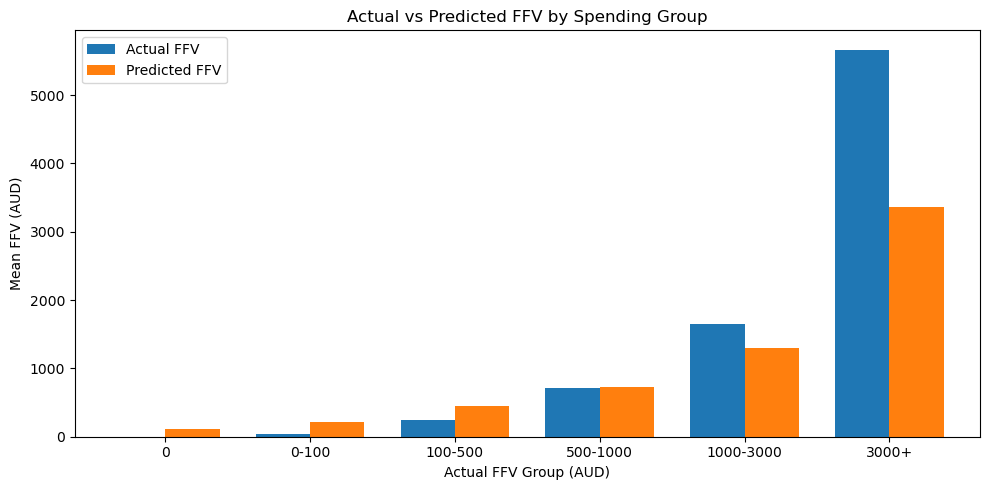

In [265]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Prepare validation results
check_df = pd.DataFrame({
    'Actual FFV': np.asarray(y_val).ravel(),
    'Predicted FFV': ols_pred
})

# Group members by actual FFV
bins = [-np.inf, 0, 100, 500, 1000, 3000, np.inf]
labels = ['0', '0-100', '100-500', '500-1000', '1000-3000', '3000+']

check_df['FFV Group'] = pd.cut(
    check_df['Actual FFV'],
    bins=bins,
    labels=labels
)

# Calculate group-level results
group_results = check_df.groupby(
    'FFV Group', observed=True
).agg(
    Members=('Actual FFV', 'size'),
    Actual_Mean=('Actual FFV', 'mean'),
    Predicted_Mean=('Predicted FFV', 'mean')
)

group_results['Bias'] = (
    group_results['Predicted_Mean'] - group_results['Actual_Mean']
)

print(group_results.round(2))

# Plot
ax = group_results[['Actual_Mean', 'Predicted_Mean']].plot(
    kind='bar',
    figsize=(10, 5),
    width=0.75
)

plt.title('Actual vs Predicted FFV by Spending Group')
plt.xlabel('Actual FFV Group (AUD)')
plt.ylabel('Mean FFV (AUD)')
plt.xticks(rotation=0)
plt.legend(['Actual FFV', 'Predicted FFV'])
plt.tight_layout()
plt.show()